<a href="https://colab.research.google.com/github/NancyWangareh/ReCover/blob/main/Recommendation_system.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## ReCover Insurance Recommedation System

## 0. Setup and load the dataset

In [2]:
%pip install pandas numpy matplotlib seaborn scipy scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme()  # Uses a readable default theme; no custom color palette is imposed.
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)




In [3]:
#connect with drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
DATA_PATH = Path("/content/drive/MyDrive/ReCover/Recommendation_system/Data/Traders_dataset_5000 (2).csv")
df = pd.read_csv(DATA_PATH)

print("Rows, columns:", df.shape)
display(df.tail())
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(1),
    "unique_values": df.nunique(dropna=True)
}).sort_values("missing_pct", ascending=False))

Rows, columns: (5000, 48)


,trader_id,age,gender,education_level,language_pref,dependents,is_main_breadwinner,county,market_name,role,stall_type,mitumba_category,years_in_trade,num_employees,monthly_income_kes,income_variability,income_receipt_pattern,preferred_premium_frequency,restock_cycle_days,owns_stock,stock_value_kes,has_electrical_connection,market_association_member,has_kra_pin,uses_mpesa,mpesa_monthly_volume_kes,smartphone_owner,whatsapp_user,preferred_channel,wants_cover_fire,wants_cover_theft,wants_cover_health,wants_cover_weather_flood,wants_cover_accident,primary_risk_concern,total_loss_24m_kes,primary_coping_mechanism,sacco_member,has_outstanding_loan,sha_status,prior_microinsurance,lapse_reason,insurance_awareness_score,trust_in_insurers_score,income_tier,wtp_monthly_kes,wtp_weekly_kes,wtp_per_payment_kes
4995,S4706,28,male,primary,swahili,1,True,Nairobi,Gikomba Market,owner,permanent_shop,shoes_bags,9,3,106500,low,weekly,weekly,14,True,219000,True,False,False,True,574500,True,True,ussd,True,False,True,False,False,health,17500,sacco_or_loan,True,False,not_registered,lapsed,slow_claims,4,4,high,863,199,199
4996,S4707,30,male,primary,english,2,False,Nairobi,Toi Market,owner,open_air_stall,bedding_linen,10,3,81500,high,monthly,monthly,14,True,194500,True,False,False,True,186500,True,True,whatsapp,True,False,False,False,False,fire,115000,absorb_from_profits,False,True,registered_not_paying,lapsed,too_expensive,2,1,high,1142,264,1142
4997,S4708,44,male,tertiary_vocational,sheng,2,False,Nairobi,Gikomba Market,owner,permanent_shop,mixed_clothing,4,3,90500,medium,daily,pay_at_restock,30,True,281000,True,True,True,True,172500,True,True,whatsapp,True,False,False,False,False,fire,126500,absorb_from_profits,False,False,not_registered,never,not_applicable,3,2,high,761,176,761
4998,S4709,36,male,primary,sheng,4,True,Mombasa,Kongowea Market,owner,permanent_shop,mens_wear,4,2,109000,low,weekly,daily,21,True,355000,True,True,True,True,246500,True,True,either,True,False,False,False,False,fire,0,sacco_or_loan,True,True,not_registered,never,not_applicable,1,4,high,896,207,30
4999,S4710,21,female,tertiary_vocational,swahili,1,False,Nairobi,Toi Market,owner,semi_permanent_stall,childrens_wear,2,0,41500,medium,weekly,pay_at_restock,21,True,144500,False,False,False,True,186000,True,True,ussd,False,True,False,False,False,theft,47000,sacco_or_loan,False,False,registered_not_paying,lapsed,slow_claims,5,1,middle,880,203,616


,dtype,missing_count,missing_pct,unique_values
trader_id,object,0,0.0,5000
age,int64,0,0.0,35
gender,object,0,0.0,2
education_level,object,0,0.0,3
language_pref,object,0,0.0,3
dependents,int64,0,0.0,8
is_main_breadwinner,bool,0,0.0,2
county,object,0,0.0,2
market_name,object,0,0.0,5
role,object,0,0.0,1


## 1. Data quality checks

In [5]:
# 1A. Duplicate records and IDs
print("Duplicate full rows:", df.duplicated().sum())
if "trader_id" in df.columns:
    print("Duplicate trader IDs:", df["trader_id"].duplicated().sum())

# 1B. Review category values (helps catch spelling/case inconsistencies)
categorical_cols = df.select_dtypes(include=["object", "bool", "category"]).columns
for col in categorical_cols:
    print(f"\\n{col}:")
    display(df[col].value_counts(dropna=False).rename_axis(col).reset_index(name="count"))

# 1C. Numeric summaries and potential outliers
display(df.select_dtypes(include=np.number).describe().T)

# 1D. Basic consistency checks; investigate flagged records rather than deleting automatically.
checks = {}
if {"wtp_monthly_kes", "wtp_per_payment_kes"}.issubset(df.columns):
    checks["per_payment_gt_monthly_wtp"] = df["wtp_per_payment_kes"] > df["wtp_monthly_kes"]
if {"smartphone_owner", "whatsapp_user", "preferred_channel"}.issubset(df.columns):
    checks["no_smartphone_but_whatsapp_preferred"] = (
        (~df["smartphone_owner"].astype("boolean").fillna(False)) &
        (df["preferred_channel"].astype(str).str.lower() == "whatsapp")
    )
    checks["not_whatsapp_user_but_whatsapp_preferred"] = (
        (~df["whatsapp_user"].astype("boolean").fillna(False)) &
        (df["preferred_channel"].astype(str).str.lower() == "whatsapp")
    )

for label, mask in checks.items():
    print(label, ":", int(mask.fillna(False).sum()), "records")
    display(df.loc[mask.fillna(False)].head(10))

Duplicate full rows: 0
Duplicate trader IDs: 0
\ntrader_id:


,trader_id,count
0,T0109,1
1,T0925,1
2,T0366,1
3,T0322,1
4,T0069,1
...,...,...
4995,S4706,1
4996,S4707,1
4997,S4708,1
4998,S4709,1


\ngender:


,gender,count
0,female,2542
1,male,2458


\neducation_level:


,education_level,count
0,secondary,2598
1,primary,1306
2,tertiary_vocational,1096


... (65 outputs left out)

no_smartphone_but_whatsapp_preferred : 0 records


,trader_id,age,gender,education_level,language_pref,dependents,is_main_breadwinner,county,market_name,role,stall_type,mitumba_category,years_in_trade,num_employees,monthly_income_kes,income_variability,income_receipt_pattern,preferred_premium_frequency,restock_cycle_days,owns_stock,stock_value_kes,has_electrical_connection,market_association_member,has_kra_pin,uses_mpesa,mpesa_monthly_volume_kes,smartphone_owner,whatsapp_user,preferred_channel,wants_cover_fire,wants_cover_theft,wants_cover_health,wants_cover_weather_flood,wants_cover_accident,primary_risk_concern,total_loss_24m_kes,primary_coping_mechanism,sacco_member,has_outstanding_loan,sha_status,prior_microinsurance,lapse_reason,insurance_awareness_score,trust_in_insurers_score,income_tier,wtp_monthly_kes,wtp_weekly_kes,wtp_per_payment_kes


not_whatsapp_user_but_whatsapp_preferred : 0 records


,trader_id,age,gender,education_level,language_pref,dependents,is_main_breadwinner,county,market_name,role,stall_type,mitumba_category,years_in_trade,num_employees,monthly_income_kes,income_variability,income_receipt_pattern,preferred_premium_frequency,restock_cycle_days,owns_stock,stock_value_kes,has_electrical_connection,market_association_member,has_kra_pin,uses_mpesa,mpesa_monthly_volume_kes,smartphone_owner,whatsapp_user,preferred_channel,wants_cover_fire,wants_cover_theft,wants_cover_health,wants_cover_weather_flood,wants_cover_accident,primary_risk_concern,total_loss_24m_kes,primary_coping_mechanism,sacco_member,has_outstanding_loan,sha_status,prior_microinsurance,lapse_reason,insurance_awareness_score,trust_in_insurers_score,income_tier,wtp_monthly_kes,wtp_weekly_kes,wtp_per_payment_kes


## 2. Risk profiling

### 2A. Primary risk concern

The bar chart shows the number of traders in each primary-risk category. These are counts in the dataset, not population estimates.

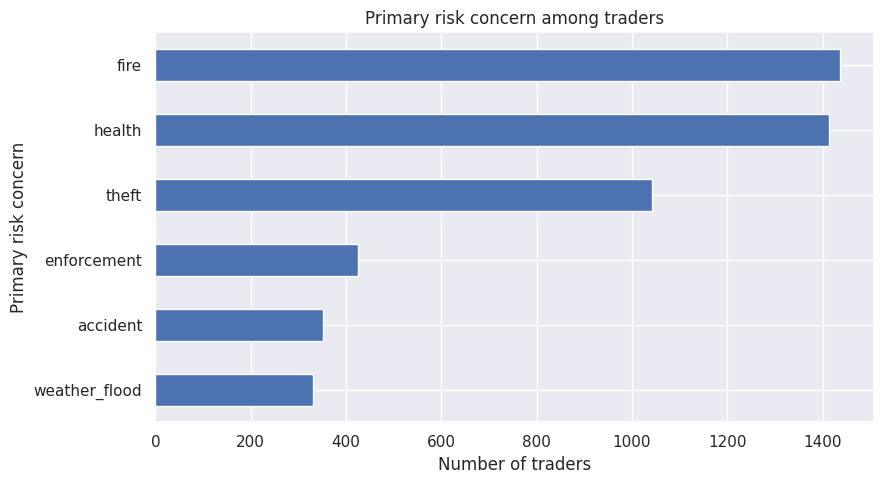

,traders,percent
primary_risk_concern,,
fire,1436,28.7
health,1413,28.3
theft,1042,20.8
enforcement,426,8.5
accident,352,7.0
weather_flood,331,6.6


In [6]:
risk_counts = df["primary_risk_concern"].fillna("missing").value_counts().sort_values(ascending=True)
ax = risk_counts.plot(kind="barh", figsize=(9, 5))
ax.set_title("Primary risk concern among traders")
ax.set_xlabel("Number of traders")
ax.set_ylabel("Primary risk concern")
plt.tight_layout()
plt.show()

risk_summary = risk_counts.rename("traders").to_frame()
risk_summary["percent"] = (risk_summary["traders"] / len(df) * 100).round(1)
display(risk_summary.sort_values("traders", ascending=False))

### 2B. Interest in different types of cover

,cover_type,interested_count,valid_responses,percent_of_valid
0,Fire,2847,5000,56.9
2,Health,2739,5000,54.8
1,Theft,2336,5000,46.7
4,Accident,1453,5000,29.1
3,Weather / flood,1009,5000,20.2


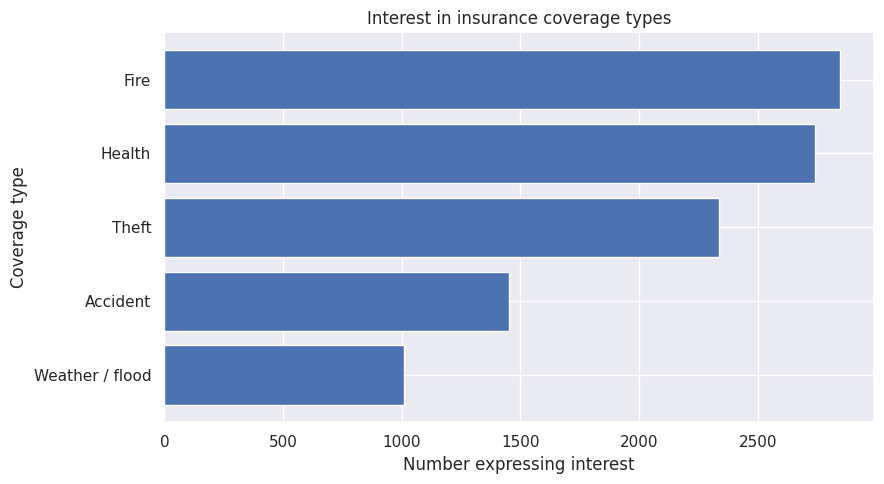

In [7]:
cover_cols = [
    "wants_cover_fire", "wants_cover_theft", "wants_cover_health",
    "wants_cover_weather_flood", "wants_cover_accident"
]
cover_labels = {
    "wants_cover_fire": "Fire",
    "wants_cover_theft": "Theft",
    "wants_cover_health": "Health",
    "wants_cover_weather_flood": "Weather / flood",
    "wants_cover_accident": "Accident"
}
available_cover_cols = [c for c in cover_cols if c in df.columns]
cover_summary = pd.DataFrame({
    "cover_type": [cover_labels[c] for c in available_cover_cols],
    "interested_count": [df[c].eq(True).sum() for c in available_cover_cols],
    "valid_responses": [df[c].notna().sum() for c in available_cover_cols]
})
cover_summary["percent_of_valid"] = (
    cover_summary["interested_count"] / cover_summary["valid_responses"] * 100
).round(1)
display(cover_summary.sort_values("interested_count", ascending=False))

plot_data = cover_summary.sort_values("interested_count")
plt.figure(figsize=(9, 5))
plt.barh(plot_data["cover_type"], plot_data["interested_count"])
plt.title("Interest in insurance coverage types")
plt.xlabel("Number expressing interest")
plt.ylabel("Coverage type")
plt.tight_layout()
plt.show()

## 3. Income variability and premium-payment preferences

### 3A. Income variability × preferred payment frequency

A 100% stacked bar chart compares payment preferences *within* each income-variability group.

preferred_premium_frequency,daily,monthly,pay_at_restock,weekly
income_variability,,,,
high,30.0,16.7,16.1,37.1
low,17.9,23.8,20.0,38.2
medium,15.3,22.6,22.5,39.5


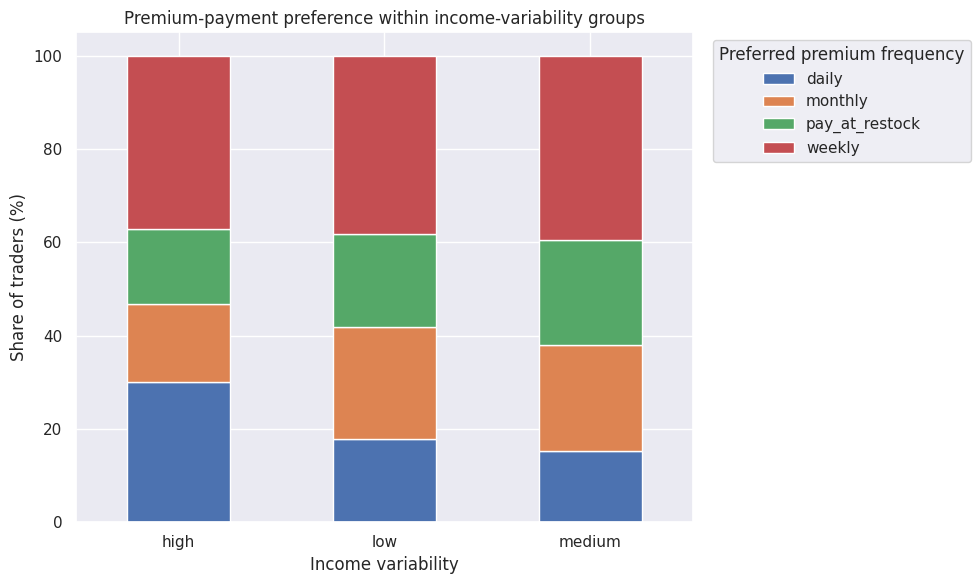

In [8]:
payment_col = "preferred_premium_frequency"
variability_col = "income_variability"
ct = pd.crosstab(df[variability_col], df[payment_col], normalize="index") * 100
display(ct.round(1))

ax = ct.plot(kind="bar", stacked=True, figsize=(10, 6))
ax.set_title("Premium-payment preference within income-variability groups")
ax.set_xlabel("Income variability")
ax.set_ylabel("Share of traders (%)")
ax.legend(title="Preferred premium frequency", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 3B. Restocking cycle and amount willing to pay per payment

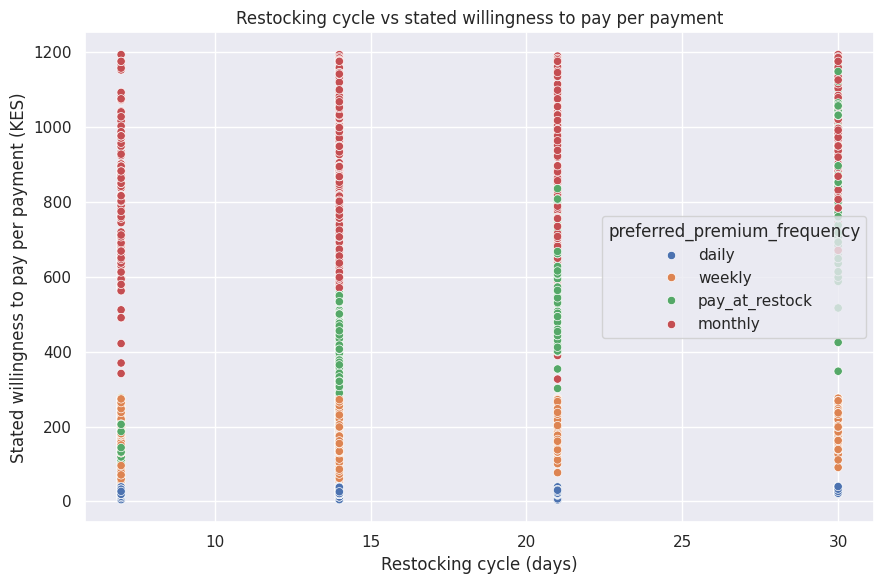

,traders,median_restock_days,median_wtp_per_payment,median_monthly_wtp
preferred_premium_frequency,,,,
weekly,1936,14.0,202.0,874.0
monthly,1114,14.0,877.5,877.5
pay_at_restock,1039,14.0,413.0,807.0
daily,911,14.0,29.0,868.0


In [9]:
required = {"restock_cycle_days", "wtp_per_payment_kes", "preferred_premium_frequency"}
if required.issubset(df.columns):
    plot_df = df[list(required)].dropna()
    plt.figure(figsize=(9, 6))
    sns.scatterplot(
        data=plot_df,
        x="restock_cycle_days",
        y="wtp_per_payment_kes",
        hue="preferred_premium_frequency"
    )
    plt.title("Restocking cycle vs stated willingness to pay per payment")
    plt.xlabel("Restocking cycle (days)")
    plt.ylabel("Stated willingness to pay per payment (KES)")
    plt.tight_layout()
    plt.show()
else:
    print("Required columns not found:", required - set(df.columns))

# Compare median values by preferred payment frequency
display(df.groupby("preferred_premium_frequency", dropna=False).agg(
    traders=("trader_id", "count"),
    median_restock_days=("restock_cycle_days", "median"),
    median_wtp_per_payment=("wtp_per_payment_kes", "median"),
    median_monthly_wtp=("wtp_monthly_kes", "median")
).sort_values("traders", ascending=False))

## 4. Insurance lapse reasons

Filter to traders whose prior microinsurance status is `lapsed`, then summarize the recorded reasons. Check category labels in the data-quality section first.

Traders recorded as lapsed: 949


,percent,count
lapse_reason,,
slow_claims,18.1,172
too_expensive,21.0,199
claim_rejected_unclear_terms,28.6,271
stopped_paying_other,32.3,307


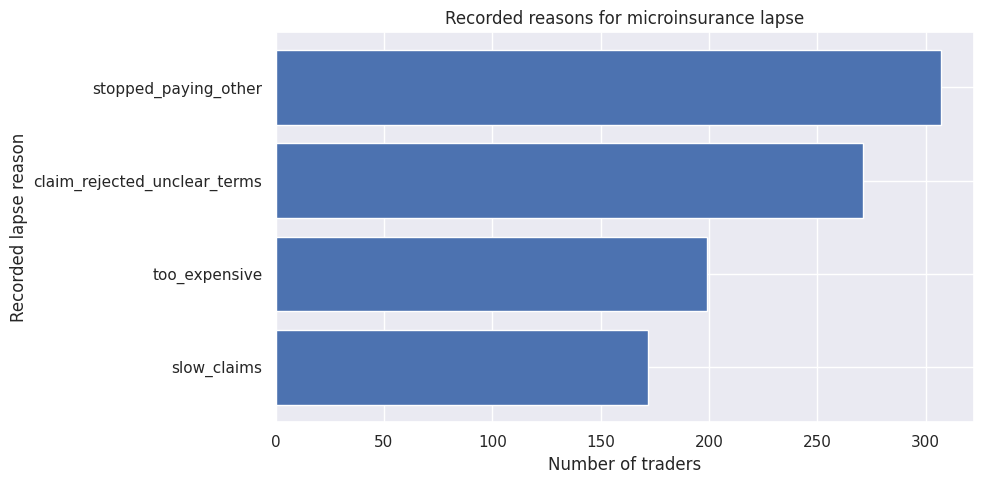

In [10]:
lapsed = df[df["prior_microinsurance"].astype(str).str.lower().eq("lapsed")].copy()
print("Traders recorded as lapsed:", len(lapsed))

if len(lapsed) and "lapse_reason" in lapsed.columns:
    lapse_counts = lapsed["lapse_reason"].fillna("missing").value_counts().sort_values()
    display((lapse_counts / len(lapsed) * 100).round(1).rename("percent").to_frame()
            .join(lapse_counts.rename("count")))
    plt.figure(figsize=(10, 5))
    plt.barh(lapse_counts.index, lapse_counts.values)
    plt.title("Recorded reasons for microinsurance lapse")
    plt.xlabel("Number of traders")
    plt.ylabel("Recorded lapse reason")
    plt.tight_layout()
    plt.show()
else:
    print("No lapsed records or lapse_reason column available.")

## 5. Insurance awareness and trust by insurance history

Compare score distributions by prior insurance status. Means/medians are descriptive; small groups should be interpreted cautiously.

insurance_awareness_score              trust_in_insurers_score             
                                         count  mean median                   count  mean median
prior_microinsurance                                                                            
active                                     285  3.48    4.0                     285  3.56    4.0
lapsed                                     949  3.50    4.0                     949  2.56    2.0
never                                     3766  2.46    2.0                    3766  3.05    3.0

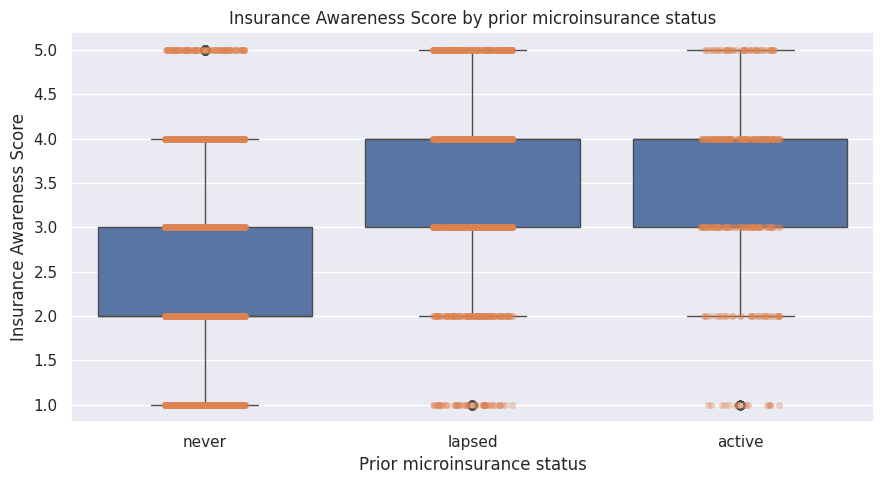

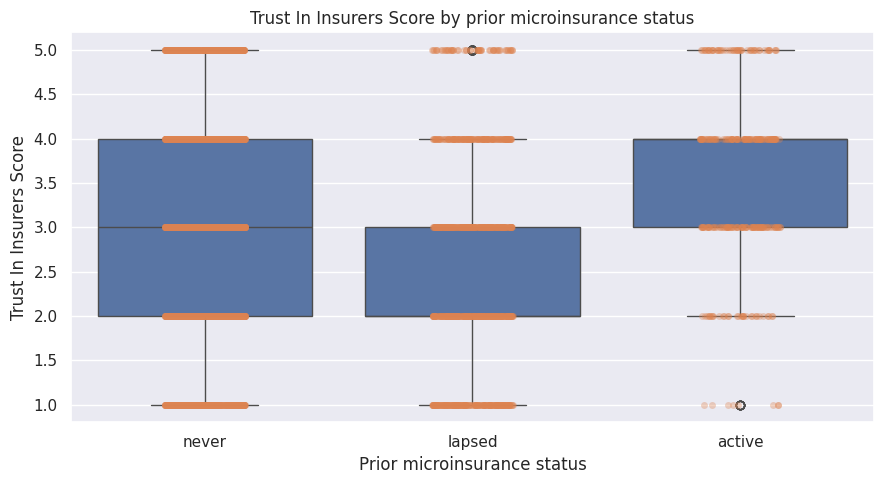

In [11]:
score_cols = ["insurance_awareness_score", "trust_in_insurers_score"]
available_scores = [c for c in score_cols if c in df.columns]

if available_scores:
    summary = df.groupby("prior_microinsurance", dropna=False)[available_scores].agg(["count", "mean", "median"]).round(2)
    display(summary)

    for score in available_scores:
        plt.figure(figsize=(9, 5))
        sns.boxplot(data=df, x="prior_microinsurance", y=score)
        sns.stripplot(data=df, x="prior_microinsurance", y=score, alpha=0.35, jitter=0.15)
        plt.title(f"{score.replace('_', ' ').title()} by prior microinsurance status")
        plt.xlabel("Prior microinsurance status")
        plt.ylabel(score.replace("_", " ").title())
        plt.tight_layout()
        plt.show()

## 6. Digital access, preferred channel and language

### 6A. Overall preferred channel

,count,percent
preferred_channel,,
ussd,1861,37.2
whatsapp,1841,36.8
either,1298,26.0


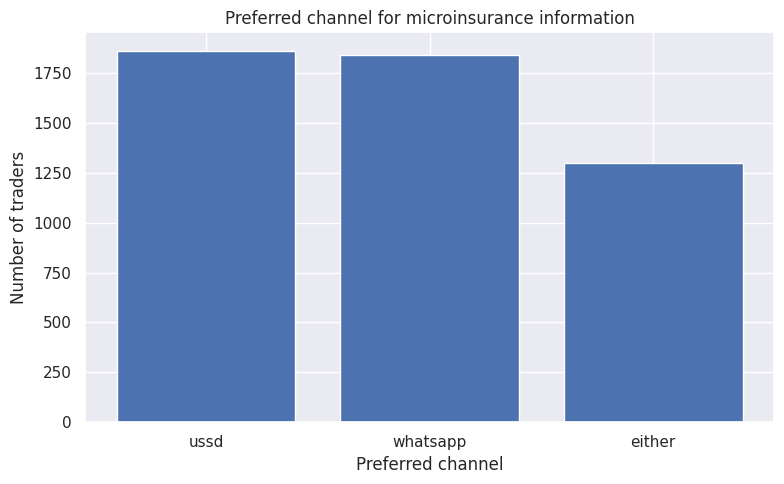

smartphone_owner,False,True,All
preferred_channel,,,
either,17,1281,1298
ussd,230,1631,1861
whatsapp,0,1841,1841
All,247,4753,5000


whatsapp_user,False,True,All
preferred_channel,,,
either,113,1185,1298
ussd,483,1378,1861
whatsapp,0,1841,1841
All,596,4404,5000


In [12]:
channel_counts = df["preferred_channel"].fillna("missing").value_counts()
channel_pct = (channel_counts / channel_counts.sum() * 100).round(1)
display(pd.DataFrame({"count": channel_counts, "percent": channel_pct}))

plt.figure(figsize=(8, 5))
plt.bar(channel_counts.index, channel_counts.values)
plt.title("Preferred channel for microinsurance information")
plt.xlabel("Preferred channel")
plt.ylabel("Number of traders")
plt.tight_layout()
plt.show()

# Access checks: ownership/use versus stated channel preference
access_cols = ["smartphone_owner", "whatsapp_user"]
display(pd.crosstab(df["preferred_channel"], df["smartphone_owner"], margins=True))
display(pd.crosstab(df["preferred_channel"], df["whatsapp_user"], margins=True))

### 6B. Preferred language × channel preference (row percentages)

preferred_channel,either,ussd,whatsapp
language_pref,,,
english,28.4,36.3,35.3
sheng,20.4,46.6,32.9
swahili,27.2,33.1,39.7


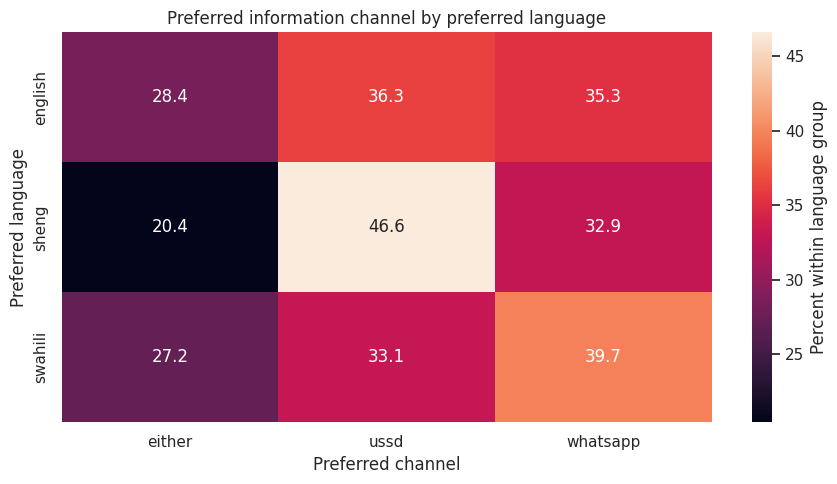

In [13]:
lang_channel = pd.crosstab(df["language_pref"], df["preferred_channel"], normalize="index") * 100
display(lang_channel.round(1))

plt.figure(figsize=(9, 5))
sns.heatmap(lang_channel, annot=True, fmt=".1f", cbar_kws={"label": "Percent within language group"})
plt.title("Preferred information channel by preferred language")
plt.xlabel("Preferred channel")
plt.ylabel("Preferred language")
plt.tight_layout()
plt.show()

## 7. Exploratory trader segmentation

This section creates transparent, rule-based *candidate* segments for exploration. The rules are illustrative and should be reviewed with traders and insurance providers before being used operationally. A trader may fit more than one segment.

,segment,traders,percent_of_dataset
0,high_stock_exposure,1255,25.1
1,cash_flow_constrained_candidate,669,13.4
2,information_seeking_candidate,2193,43.9
3,previously_lapsed,949,19.0
4,digital_access_constraint_candidate,596,11.9


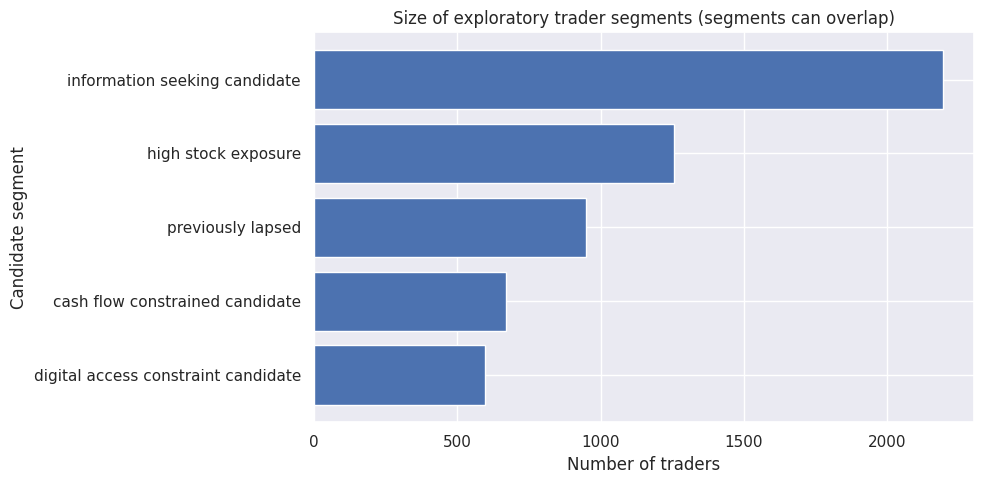

,segment,traders,median_monthly_income_kes,median_stock_value_kes,median_monthly_wtp_kes,most_common_primary_risk,most_common_channel
0,high_stock_exposure,1255,92000.0,308000.0,1006.0,health,ussd
1,cash_flow_constrained_candidate,669,39500.0,127500.0,700.0,health,either
2,information_seeking_candidate,2193,61000.0,173000.0,868.0,fire,ussd
3,previously_lapsed,949,50500.0,157000.0,861.0,fire,ussd
4,digital_access_constraint_candidate,596,57750.0,178000.0,850.5,health,ussd


In [14]:
seg = df.copy()

# Normalize booleans robustly if values are already booleans or contain strings.
def as_bool(series):
    if pd.api.types.is_bool_dtype(series):
        return series
    return series.astype(str).str.strip().str.lower().map({
        "true": True, "1": True, "yes": True,
        "false": False, "0": False, "no": False
    })

seg["high_stock_exposure"] = (
    seg["stock_value_kes"].ge(seg["stock_value_kes"].quantile(0.75))
    if "stock_value_kes" in seg else False
)
seg["cash_flow_constrained_candidate"] = (
    seg["income_variability"].astype(str).str.lower().eq("high")
)
seg["information_seeking_candidate"] = (
    seg["insurance_awareness_score"].le(2)
    if "insurance_awareness_score" in seg else False
)
seg["previously_lapsed"] = seg["prior_microinsurance"].astype(str).str.lower().eq("lapsed")
seg["digital_access_constraint_candidate"] = (
    (~as_bool(seg["smartphone_owner"]).fillna(False)) |
    (~as_bool(seg["whatsapp_user"]).fillna(False))
)

# Summarize overlap: these segments are not mutually exclusive.
segment_cols = [
    "high_stock_exposure", "cash_flow_constrained_candidate",
    "information_seeking_candidate", "previously_lapsed",
    "digital_access_constraint_candidate"
]
segment_summary = pd.DataFrame({
    "segment": segment_cols,
    "traders": [seg[c].fillna(False).sum() for c in segment_cols]
})
segment_summary["percent_of_dataset"] = (segment_summary["traders"] / len(seg) * 100).round(1)
display(segment_summary)

plt.figure(figsize=(10, 5))
ordered = segment_summary.sort_values("traders")
plt.barh(ordered["segment"].str.replace("_", " "), ordered["traders"])
plt.title("Size of exploratory trader segments (segments can overlap)")
plt.xlabel("Number of traders")
plt.ylabel("Candidate segment")
plt.tight_layout()
plt.show()

# Compare segment characteristics; medians are robust for skewed money variables.
segment_profiles = []
for col in segment_cols:
    group = seg[seg[col].fillna(False)]
    segment_profiles.append({
        "segment": col,
        "traders": len(group),
        "median_monthly_income_kes": group["monthly_income_kes"].median(),
        "median_stock_value_kes": group["stock_value_kes"].median(),
        "median_monthly_wtp_kes": group["wtp_monthly_kes"].median(),
        "most_common_primary_risk": group["primary_risk_concern"].mode().iat[0] if not group["primary_risk_concern"].mode().empty else np.nan,
        "most_common_channel": group["preferred_channel"].mode().iat[0] if not group["preferred_channel"].mode().empty else np.nan
    })
display(pd.DataFrame(segment_profiles).round(1))

## 8. Stated willingness to pay and financial circumstances

### 8A. Monthly income vs stated monthly willingness to pay

Use a scatter plot and Spearman correlation. Correlation is association, not causation.

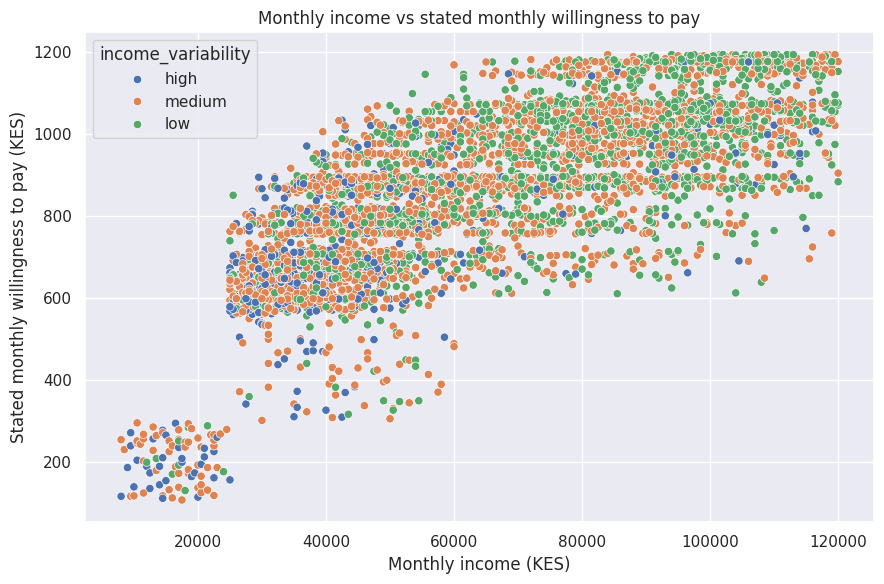

,monthly_income_kes,wtp_monthly_kes
monthly_income_kes,1.000,0.777
wtp_monthly_kes,0.777,1.000


,traders,median_income_kes,median_monthly_wtp_kes,median_wtp_per_payment_kes
income_variability,,,,
high,669,39500.0,700.0,161.0
low,1778,76000.0,930.0,244.0
medium,2553,55500.0,860.0,230.0


In [15]:
plot_cols = ["monthly_income_kes", "wtp_monthly_kes", "income_variability"]
plot_df = df[plot_cols].dropna()
plt.figure(figsize=(9, 6))
sns.scatterplot(data=plot_df, x="monthly_income_kes", y="wtp_monthly_kes", hue="income_variability")
plt.title("Monthly income vs stated monthly willingness to pay")
plt.xlabel("Monthly income (KES)")
plt.ylabel("Stated monthly willingness to pay (KES)")
plt.tight_layout()
plt.show()

display(plot_df[["monthly_income_kes", "wtp_monthly_kes"]].corr(method="spearman").round(3))

# Summarize willingness to pay across key groups
display(df.groupby("income_variability", dropna=False).agg(
    traders=("trader_id", "count"),
    median_income_kes=("monthly_income_kes", "median"),
    median_monthly_wtp_kes=("wtp_monthly_kes", "median"),
    median_wtp_per_payment_kes=("wtp_per_payment_kes", "median")
).round(1))

### 8B. Compare willingness to pay by primary risk and insurance history

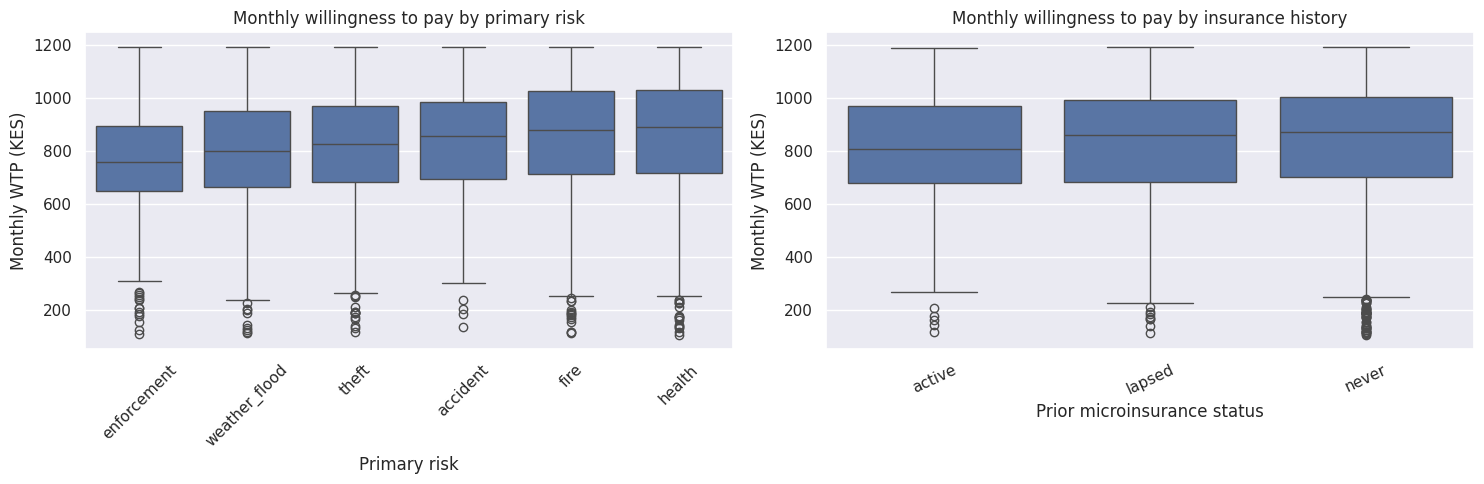

traders  median_monthly_wtp_kes  mean_monthly_wtp_kes
primary_risk_concern prior_microinsurance                                                       
accident             active                     21                   707.0                 756.7
                     lapsed                     60                   828.5                 822.4
                     never                     271                   864.0                 851.8
enforcement          active                     47                   675.0                 706.1
                     lapsed                     61                   706.0                 735.1
                     never                     318                   779.0                 784.7
fire                 active                     73                   875.0                 870.6
                     lapsed                    324                   874.0                 856.4
                     never                    1039                   884.0                 876.4
health               active                     82                   887.0                 864.7
                     lapsed                    285                   887.0                 864.8
                     never                    1046                   892.0                 877.8
theft                active                     55                   757.0                 791.0
                     lapsed                    164                   810.5                 804.1
                     never                     823                   851.0                 832.7
weather_flood        active                      7                   759.0                 608.7
                     lapsed                     55                   705.0                 746.4
                     never                     269                   818.0                 816.7

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

risk_order = df.groupby("primary_risk_concern")["wtp_monthly_kes"].median().sort_values().index
sns.boxplot(data=df, x="primary_risk_concern", y="wtp_monthly_kes", order=risk_order, ax=axes[0])
axes[0].set_title("Monthly willingness to pay by primary risk")
axes[0].set_xlabel("Primary risk")
axes[0].set_ylabel("Monthly WTP (KES)")
axes[0].tick_params(axis="x", rotation=45)

status_order = df.groupby("prior_microinsurance")["wtp_monthly_kes"].median().sort_values().index
sns.boxplot(data=df, x="prior_microinsurance", y="wtp_monthly_kes", order=status_order, ax=axes[1])
axes[1].set_title("Monthly willingness to pay by insurance history")
axes[1].set_xlabel("Prior microinsurance status")
axes[1].set_ylabel("Monthly WTP (KES)")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

# Non-parametric group comparison summaries; inspect sample sizes before interpreting.
display(df.groupby(["primary_risk_concern", "prior_microinsurance"], dropna=False).agg(
    traders=("trader_id", "count"),
    median_monthly_wtp_kes=("wtp_monthly_kes", "median"),
    mean_monthly_wtp_kes=("wtp_monthly_kes", "mean")
).round(1))

## 9. Optional: simple statistical tests

Use these only after inspecting distributions, group sizes, and data collection methods. P-values do not measure practical importance and do not establish causality.

In [17]:
from scipy.stats import spearmanr, kruskal, chi2_contingency

# Spearman association between income and monthly willingness to pay
tmp = df[["monthly_income_kes", "wtp_monthly_kes"]].dropna()
if len(tmp) >= 3:
    rho, p = spearmanr(tmp["monthly_income_kes"], tmp["wtp_monthly_kes"])
    print(f"Spearman income-WTP: rho={rho:.3f}, p={p:.4g}, n={len(tmp)}")

# Kruskal-Wallis test: monthly WTP across income-variability groups
groups = [
    g["wtp_monthly_kes"].dropna().values
    for _, g in df.groupby("income_variability")
    if g["wtp_monthly_kes"].notna().sum() > 0
]
if len(groups) >= 2 and all(len(g) > 0 for g in groups):
    stat, p = kruskal(*groups)
    print(f"Kruskal-Wallis WTP by income variability: H={stat:.3f}, p={p:.4g}")

# Chi-square: preferred channel vs preferred language
ct = pd.crosstab(df["language_pref"], df["preferred_channel"])
if ct.shape[0] > 1 and ct.shape[1] > 1:
    chi2, p, dof, expected = chi2_contingency(ct)
    print(f"Chi-square language-channel: chi2={chi2:.3f}, dof={dof}, p={p:.4g}")
    print("Check expected cell counts before interpreting this test.")

Spearman income-WTP: rho=0.777, p=0, n=5000
Kruskal-Wallis WTP by income variability: H=478.368, p=1.33e-104
Chi-square language-channel: chi2=69.038, dof=4, p=3.623e-14
Check expected cell counts before interpreting this test.


## 10. Export summary tables

This writes analysis tables to an `outputs` folder. Charts can be saved individually by adding `plt.savefig(...)` before each `plt.show()`.

In [18]:
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

df.isna().sum().rename("missing_count").to_csv(OUTPUT_DIR / "missing_values.csv")
risk_summary.to_csv(OUTPUT_DIR / "primary_risk_summary.csv")
cover_summary.to_csv(OUTPUT_DIR / "coverage_interest_summary.csv")
ct.to_csv(OUTPUT_DIR / "last_crosstab.csv")

print(f"Summary tables exported to: {OUTPUT_DIR.resolve()}")

Summary tables exported to: /content/outputs


Trader Segmentation - K-means Clustering

In [19]:
features = [
    "primary_risk_concern",
    "wants_cover_fire",
    "wants_cover_theft",
    "stock_value_kes",
    "total_loss_24m_kes",
    "monthly_income_kes",
    "income_variability",
    "wtp_monthly_kes",
    "preferred_premium_frequency",
    "income_receipt_pattern",
    "restock_cycle_days"
]

display(df[features].describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
primary_risk_concern,5000,6,fire,1436,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wants_cover_fire,5000,2,True,2847,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wants_cover_theft,5000,2,False,2664,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stock_value_kes,5000.0,NaN,NaN,NaN,188823.7,94127.215803,15000.0,118500.0,170000.0,246000.0,450000.0
total_loss_24m_kes,5000.0,NaN,NaN,NaN,28393.9,52065.566908,0.0,0.0,6000.0,35500.0,354000.0
monthly_income_kes,5000.0,NaN,NaN,NaN,63578.2,26473.81456,8000.0,41000.0,59000.0,86000.0,120000.0
income_variability,5000,3,medium,2553,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wtp_monthly_kes,5000.0,NaN,NaN,NaN,847.3046,200.544249,108.0,697.75,868.0,1002.0,1194.0
preferred_premium_frequency,5000,4,weekly,1936,NaN,NaN,NaN,NaN,NaN,NaN,NaN
income_receipt_pattern,5000,3,daily,3830,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

numeric_features = [
    "stock_value_kes",
    "total_loss_24m_kes",
    "monthly_income_kes",
    "wtp_monthly_kes",
    "restock_cycle_days"
]

categorical_features = [
    "primary_risk_concern",
    "wants_cover_fire",
    "wants_cover_theft",
    "income_variability",
    "preferred_premium_frequency",
    "income_receipt_pattern"
]

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X = df[numeric_features + categorical_features]

X_processed = preprocessor.fit_transform(X)

print("Original shape:", X.shape)
print("Processed shape:", X_processed.shape)

Original shape: (5000, 11)
Processed shape: (5000, 25)


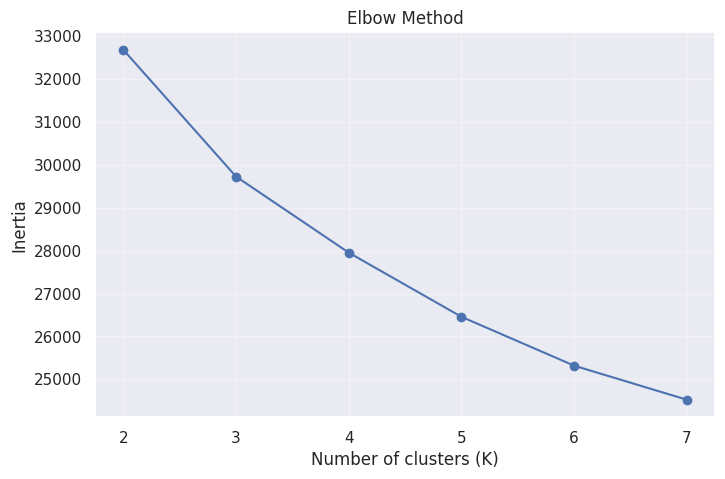

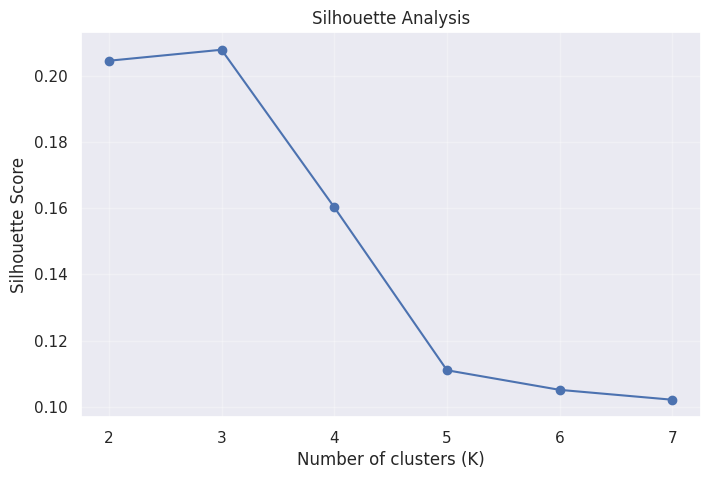

K=2: Silhouette Score=0.205
K=3: Silhouette Score=0.208
K=4: Silhouette Score=0.160
K=5: Silhouette Score=0.111
K=6: Silhouette Score=0.105
K=7: Silhouette Score=0.102


In [21]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia_values = []
silhouette_values = []
k_values = range(2, 8)

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_processed)

    inertia_values.append(model.inertia_)
    silhouette_values.append(
        silhouette_score(X_processed, labels)
    )

# Elbow plot
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertia_values, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()

# Silhouette plot
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), silhouette_values, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()

for k, score in zip(k_values, silhouette_values):
    print(f"K={k}: Silhouette Score={score:.3f}")

In [22]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

df["cluster"] = kmeans.fit_predict(X_processed)

print(df["cluster"].value_counts().sort_index())

cluster
0     289
1    2588
2    2123
Name: count, dtype: int64


In [23]:
cluster_numeric = df.groupby("cluster")[numeric_features].median()

display(cluster_numeric.round(2))

,stock_value_kes,total_loss_24m_kes,monthly_income_kes,wtp_monthly_kes,restock_cycle_days
cluster,,,,,
0,249000.0,170500.0,83500.0,965.0,21.0
1,122500.0,7000.0,41500.0,706.0,14.0
2,246500.0,0.0,87000.0,1004.0,21.0


In [24]:
for col in categorical_features:
    print(f"\n--- {col} ---")

    distribution = pd.crosstab(
        df["cluster"],
        df[col],
        normalize="index"
    ) * 100

    display(distribution.round(1))


--- primary_risk_concern ---


primary_risk_concern,accident,enforcement,fire,health,theft,weather_flood
cluster,,,,,,
0,4.5,9.3,36.0,24.9,24.2,1.0
1,7.7,12.4,23.1,24.1,24.8,7.9
2,6.5,3.7,34.6,33.8,15.6,5.8



--- wants_cover_fire ---


wants_cover_fire,False,True
cluster,,
0,22.5,77.5
1,51.0,49.0
2,36.2,63.8



--- wants_cover_theft ---


wants_cover_theft,False,True
cluster,,
0,43.6,56.4
1,49.4,50.6
2,59.3,40.7


... (2 outputs left out)


--- preferred_premium_frequency ---


preferred_premium_frequency,daily,monthly,pay_at_restock,weekly
cluster,,,,
0,20.4,17.3,7.3,55.0
1,16.7,20.4,25.5,37.4
2,19.8,25.3,16.8,38.1



--- income_receipt_pattern ---


income_receipt_pattern,daily,monthly,weekly
cluster,,,
0,82.7,2.8,14.5
1,84.9,3.7,11.5
2,65.7,9.0,25.2


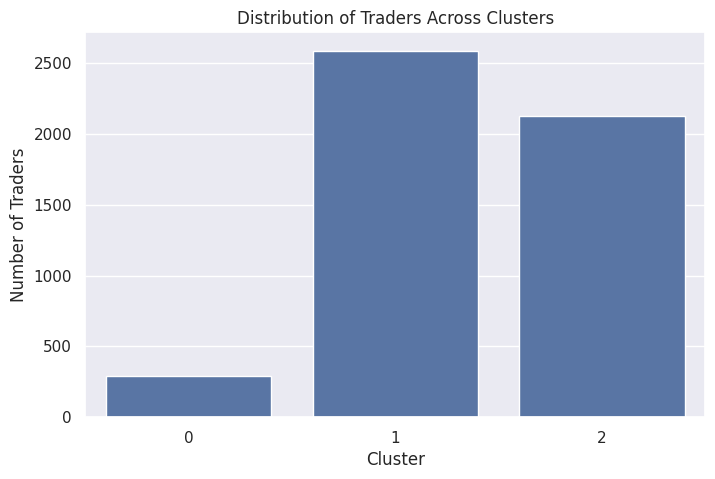

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="cluster"
)

plt.title("Distribution of Traders Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Traders")

plt.show()

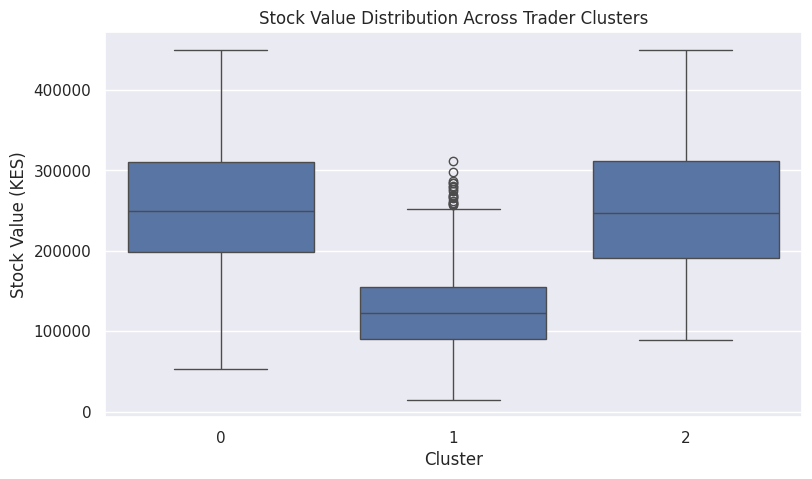

In [26]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="cluster",
    y="stock_value_kes"
)

plt.title("Stock Value Distribution Across Trader Clusters")
plt.xlabel("Cluster")
plt.ylabel("Stock Value (KES)")

plt.show()

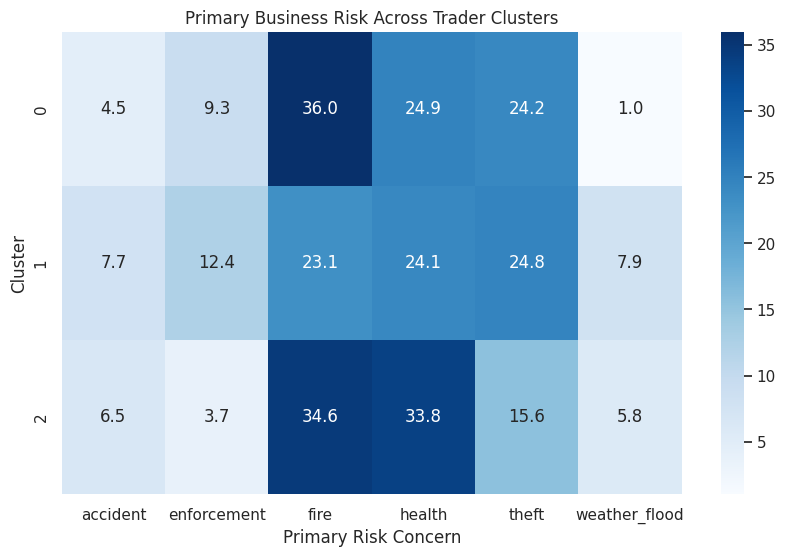

In [27]:
risk_distribution = pd.crosstab(
    df["cluster"],
    df["primary_risk_concern"],
    normalize="index"
) * 100

plt.figure(figsize=(10, 6))

sns.heatmap(
    risk_distribution,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title("Primary Business Risk Across Trader Clusters")
plt.xlabel("Primary Risk Concern")
plt.ylabel("Cluster")

plt.show()

In [28]:
from sklearn.decomposition import PCA
import pandas as pd
import numpy as np

# Initialize PCA with two components
pca = PCA(n_components=2)

# Transform the processed dataset
X_pca = pca.fit_transform(X_processed)

# Create a DataFrame containing the PCA results
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

# Add cluster assignments
pca_df["cluster"] = df["cluster"].values

# Inspect results
display(pca_df.head())

,PC1,PC2,cluster
0,-4.448946,-0.079989,1
1,-3.584135,0.292908,1
2,-4.051745,-0.262850,1
3,-4.059375,-0.129394,1
4,-4.418399,-0.282854,1


In [29]:
# Individual explained variance
explained_variance = pca.explained_variance_ratio_

# Cumulative explained variance
cumulative_variance = np.cumsum(explained_variance)

print(f"PC1: {explained_variance[0]*100:.2f}%")
print(f"PC2: {explained_variance[1]*100:.2f}%")

print(
    f"Total variance explained: "
    f"{sum(explained_variance)*100:.2f}%"
)

PC1: 31.47%
PC2: 12.05%
Total variance explained: 43.52%


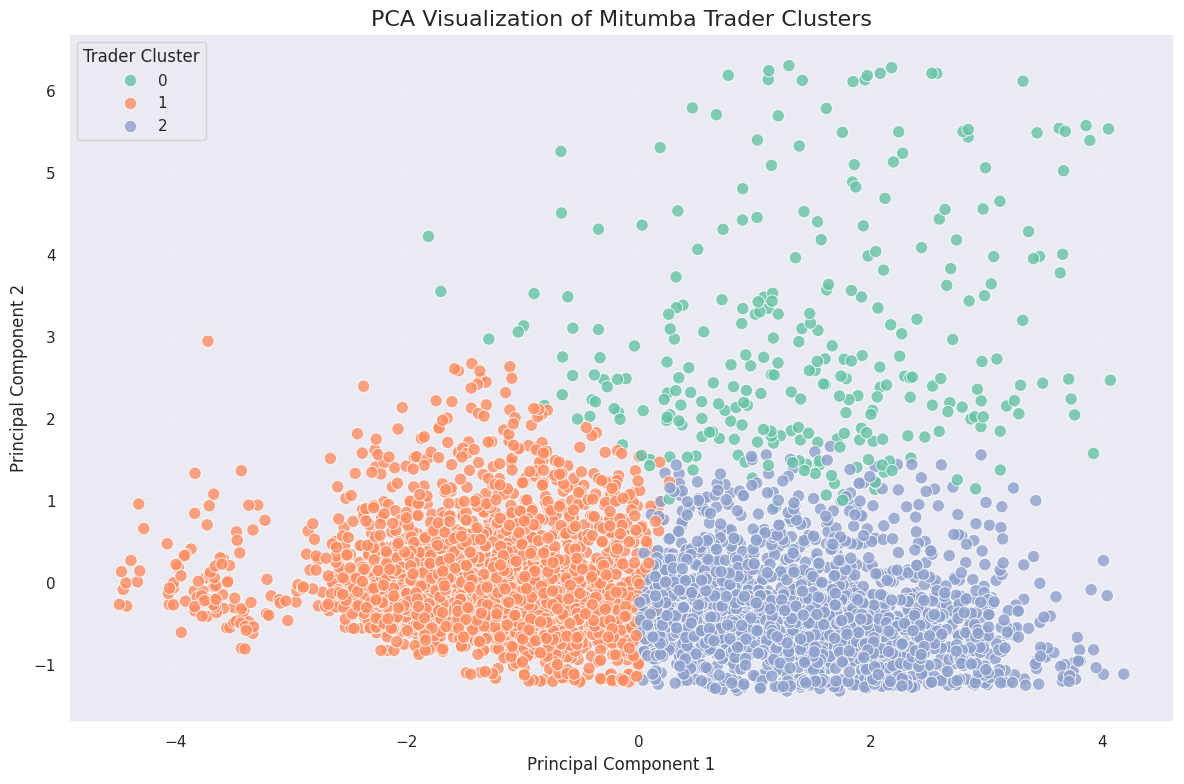

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="Set2",
    s=80,
    alpha=0.8
)

plt.title(
    "PCA Visualization of Mitumba Trader Clusters",
    fontsize=16
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend(title="Trader Cluster")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

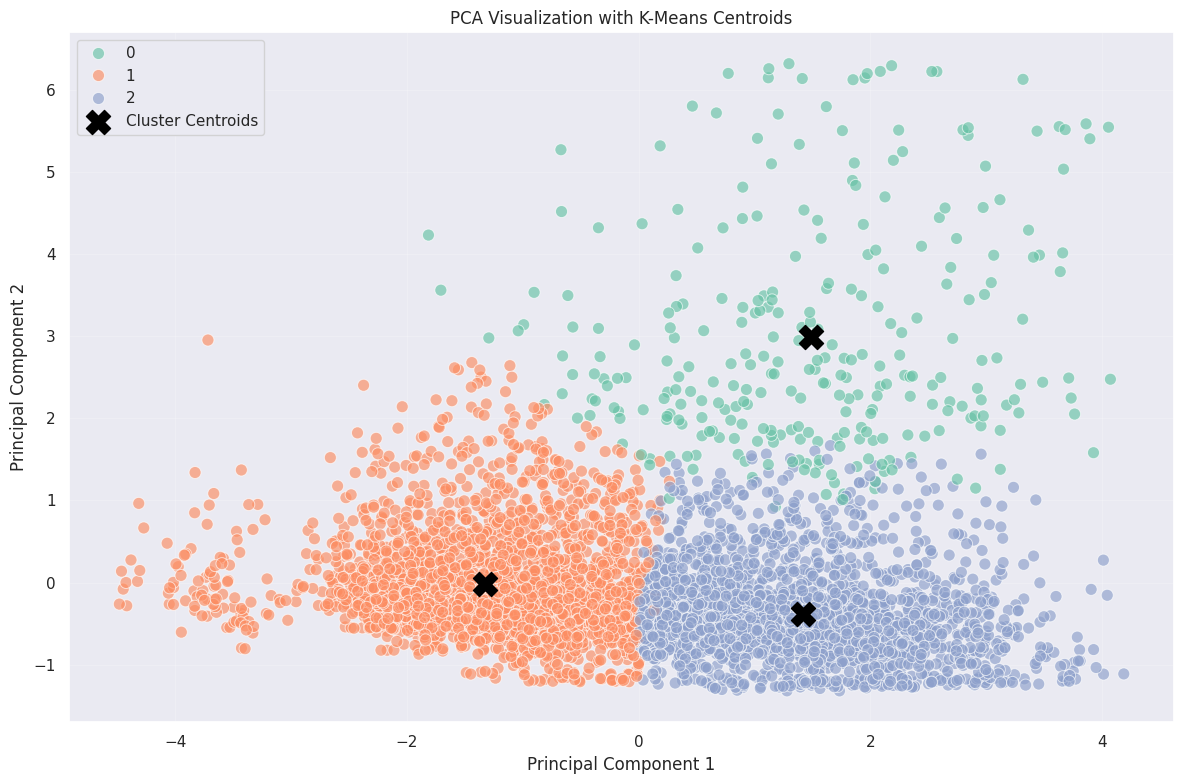

In [31]:
# Transform K-Means centroids into PCA space
centroids_pca = pca.transform(kmeans.cluster_centers_)

plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="Set2",
    s=75,
    alpha=0.65
)

# Plot centroids
plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    marker="X",
    s=300,
    color="black",
    label="Cluster Centroids"
)

plt.title("PCA Visualization with K-Means Centroids")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [32]:
# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Extract PCA loadings
loadings = pd.DataFrame(
    pca.components_.T,
    columns=["PC1", "PC2"],
    index=feature_names
)

display(loadings)

,PC1,PC2
num__stock_value_kes,0.518046,0.035016
num__total_loss_24m_kes,0.098077,0.942473
num__monthly_income_kes,0.567769,-0.008296
num__wtp_monthly_kes,0.514742,-0.008801
num__restock_cycle_days,0.319929,-0.242480
cat__primary_risk_concern_accident,-0.002706,-0.003780
cat__primary_risk_concern_enforcement,-0.027900,0.022779
cat__primary_risk_concern_fire,0.041890,-0.017940
cat__primary_risk_concern_health,0.027843,-0.038242
cat__primary_risk_concern_theft,-0.029231,0.050639


#### 11. Linking Trader Clusters to an Insurance Product Catalogue



In [33]:
# Load the actual Britam product catalogue
products_path = "/content/drive/MyDrive/ReCover/Recommendation_system/Data/microinsurance_products_dataset.csv"
product_df = pd.read_csv(products_path)

print("Product Catalogue columns and shape:", product_df.shape)
display(product_df.head(20))


Product Catalogue columns and shape: (24, 25)


,product_id,product_family,target_segment,plan_name,tier_rank,premium_kes_pa,fire_limit_kes,burglary_limit_kes,provider,cover_category,premium_rate_pct_of_stock,monthly_equivalent_kes,weekly_equivalent_kes,daily_equivalent_kes,max_single_limit_kes,fits_microinsurance_regs,reg_check_note,target_stock_min_kes,target_stock_max_kes,pct_of_290_traders_who_can_afford,pct_of_290_traders_stock_within_limit,pct_of_290_traders_afford_and_stock_covered,data_status,availability,confidence
0,BBL-ELITE,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Elite,1,6933,500000.0,500000.0,Britam,"Package (property, liability, staff)",NaN,577.75,133.33,18.99,1000000.0,no,Does not qualify as microinsurance: limit abov...,300000.0,500000.0,34.8,100.0,34.8,Published (existing catalogue),Current,High
1,BBL-PREMIUM,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Premium,2,13615,1000000.0,1000000.0,Britam,"Package (property, liability, staff)",NaN,1134.58,261.83,37.30,2000000.0,no,Does not qualify as microinsurance: limit abov...,600000.0,1000000.0,3.1,100.0,3.1,Published (existing catalogue),Current,High
2,BBL-DIAMOND,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Diamond,3,20298,1500000.0,1500000.0,Britam,"Package (property, liability, staff)",NaN,1691.50,390.35,55.61,3000000.0,no,Does not qualify as microinsurance: daily prem...,900000.0,1500000.0,0.0,100.0,0.0,Published (existing catalogue),Current,High
3,BBL-PLATINUM,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Platinum,4,26980,2000000.0,2000000.0,Britam,"Package (property, liability, staff)",NaN,2248.33,518.85,73.92,4000000.0,no,Does not qualify as microinsurance: daily prem...,1200000.0,2000000.0,0.0,100.0,0.0,Published (existing catalogue),Current,High
4,BBL-PRESTIGE,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Prestige,5,37163,3000000.0,3000000.0,Britam,"Package (property, liability, staff)",NaN,3096.92,714.67,101.82,5000000.0,no,Does not qualify as microinsurance: daily prem...,1800000.0,3000000.0,0.0,100.0,0.0,Published (existing catalogue),Current,High
5,CIC-AFYA-CASH,CIC Afya Cash (with ECLOF Kenya and Noble Stri...,"Small business owners, sole proprietors (ECLOF...",Afya Cash,1,1200,NaN,NaN,CIC,Hospital cash (income replacement),NaN,100.00,23.08,3.29,50000.0,yes,Daily premium and largest limit are within the...,NaN,NaN,100.0,NaN,NaN,Published,Current (sold through ECLOF Kenya; wider acces...,High
6,BRITAM-BIMA-WAFANYIKAZI,Britam Connect,Informal-sector workers and small business owners,Bima ya Wafanyikazi,1,4032,NaN,NaN,Britam,Medical,NaN,336.00,77.54,11.05,NaN,unknown (limits not published),Cannot be checked until the insurer publishes ...,NaN,NaN,63.1,NaN,NaN,Published headline (monthly figure x 12),Unverified (article date not captured),Medium
7,CIC-IMPACT-MSME,CIC Impact (microinsurance subsidiary),"Micro, small and medium enterprises",MSME and Commercial Risk (headline),1,3000,NaN,NaN,CIC,Small-business protection (scope not stated),NaN,250.00,57.69,8.22,NaN,unknown (limits not published),Cannot be checked until the insurer publishes ...,NaN,NaN,76.6,NaN,NaN,Published headline (upper bound),Current (launched 30 Jul 2026; product terms t...,Low
8,JUBILEE-IMARISHA-JAMII,Jubilee Imarisha Jamii,"Low-income earners; group, family and chama",Imarisha Jamii,1,7300,NaN,NaN,Jubilee,"Health and life (hospital cash, death, disabil...",NaN,608.33,140.38,20.00,NaN,unknown (limits not published),Cannot be checked until the insurer publishes ...,NaN,NaN,33.4,NaN,NaN,"Published headline, frequency unconfirmed",Unverified (2018 launch coverage),Low
9,RM-STOCK-30K,ReCover Mitumba Micro-Biashara (estimated),Mitumba and other informal market traders,Stock Shield 30K,1,500,30000.0,30000.0,"ReCover (estimate, not an insurer product)",Stock fire and burglary,1.67,41.67,9.62,1.37,30000.0,yes,Daily premium and largest limit are within the...,18000.0,30000.0,100.0,6.2,6.2,Estimated (derived from published rate),Proposed (needs an in

In [34]:
print("Top contributors to PC1:")
display(
    loadings["PC1"]
    .abs()
    .sort_values(ascending=False)
    .head(10)
)

print("Top contributors to PC2:")
display(
    loadings["PC2"]
    .abs()
    .sort_values(ascending=False)
    .head(10)
)

Top contributors to PC1:


,PC1
num__monthly_income_kes,0.567769
num__stock_value_kes,0.518046
num__wtp_monthly_kes,0.514742
num__restock_cycle_days,0.319929
cat__income_variability_low,0.099210
num__total_loss_24m_kes,0.098077
cat__income_variability_high,0.058838
cat__wants_cover_fire_True,0.053226
cat__wants_cover_fire_False,0.053226
cat__income_receipt_pattern_daily,0.052272


Top contributors to PC2:


,PC2
num__total_loss_24m_kes,0.942473
num__restock_cycle_days,0.242480
cat__wants_cover_theft_False,0.110724
cat__wants_cover_theft_True,0.110724
cat__income_variability_low,0.090944
cat__income_variability_medium,0.071929
cat__primary_risk_concern_theft,0.050639
cat__preferred_premium_frequency_weekly,0.050411
cat__income_receipt_pattern_daily,0.042052
cat__primary_risk_concern_health,0.038242


In [35]:
print('--- Top 5 Features for PC1 (Absolute Loadings) ---')
display(loadings['PC1'].abs().sort_values(ascending=False).head(5))

print('\n--- Top 5 Features for PC2 (Absolute Loadings) ---')
display(loadings['PC2'].abs().sort_values(ascending=False).head(5))

--- Top 5 Features for PC1 (Absolute Loadings) ---


,PC1
num__monthly_income_kes,0.567769
num__stock_value_kes,0.518046
num__wtp_monthly_kes,0.514742
num__restock_cycle_days,0.319929
cat__income_variability_low,0.099210



--- Top 5 Features for PC2 (Absolute Loadings) ---


,PC2
num__total_loss_24m_kes,0.942473
num__restock_cycle_days,0.242480
cat__wants_cover_theft_False,0.110724
cat__wants_cover_theft_True,0.110724
cat__income_variability_low,0.090944


#### Product matching

In [36]:
import pandas as pd
import numpy as np

# Load datasets
traders = pd.read_csv("/content/drive/MyDrive/ReCover/Recommendation_system/Data/Traders_dataset_5000 (2).csv")

products = pd.read_csv("/content/drive/MyDrive/ReCover/Recommendation_system/Data/microinsurance_products_dataset.csv")

print("Traders:", traders.shape)
print("Products:", products.shape)

display(products)

Traders: (5000, 48)
Products: (24, 25)


,product_id,product_family,target_segment,plan_name,tier_rank,premium_kes_pa,fire_limit_kes,burglary_limit_kes,provider,cover_category,premium_rate_pct_of_stock,monthly_equivalent_kes,weekly_equivalent_kes,daily_equivalent_kes,max_single_limit_kes,fits_microinsurance_regs,reg_check_note,target_stock_min_kes,target_stock_max_kes,pct_of_290_traders_who_can_afford,pct_of_290_traders_stock_within_limit,pct_of_290_traders_afford_and_stock_covered,data_status,availability,confidence
0,BBL-ELITE,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Elite,1,6933,500000.0,500000.0,Britam,"Package (property, liability, staff)",NaN,577.75,133.33,18.99,1000000.0,no,Does not qualify as microinsurance: limit abov...,300000.0,500000.0,34.8,100.0,34.8,Published (existing catalogue),Current,High
1,BBL-PREMIUM,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Premium,2,13615,1000000.0,1000000.0,Britam,"Package (property, liability, staff)",NaN,1134.58,261.83,37.30,2000000.0,no,Does not qualify as microinsurance: limit abov...,600000.0,1000000.0,3.1,100.0,3.1,Published (existing catalogue),Current,High
2,BBL-DIAMOND,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Diamond,3,20298,1500000.0,1500000.0,Britam,"Package (property, liability, staff)",NaN,1691.50,390.35,55.61,3000000.0,no,Does not qualify as microinsurance: daily prem...,900000.0,1500000.0,0.0,100.0,0.0,Published (existing catalogue),Current,High
3,BBL-PLATINUM,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Platinum,4,26980,2000000.0,2000000.0,Britam,"Package (property, liability, staff)",NaN,2248.33,518.85,73.92,4000000.0,no,Does not qualify as microinsurance: daily prem...,1200000.0,2000000.0,0.0,100.0,0.0,Published (existing catalogue),Current,High
4,BBL-PRESTIGE,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Prestige,5,37163,3000000.0,3000000.0,Britam,"Package (property, liability, staff)",NaN,3096.92,714.67,101.82,5000000.0,no,Does not qualify as microinsurance: daily prem...,1800000.0,3000000.0,0.0,100.0,0.0,Published (existing catalogue),Current,High
5,CIC-AFYA-CASH,CIC Afya Cash (with ECLOF Kenya and Noble Stri...,"Small business owners, sole proprietors (ECLOF...",Afya Cash,1,1200,NaN,NaN,CIC,Hospital cash (income replacement),NaN,100.00,23.08,3.29,50000.0,yes,Daily premium and largest limit are within the...,NaN,NaN,100.0,NaN,NaN,Published,Current (sold through ECLOF Kenya; wider acces...,High
6,BRITAM-BIMA-WAFANYIKAZI,Britam Connect,Informal-sector workers and small business owners,Bima ya Wafanyikazi,1,4032,NaN,NaN,Britam,Medical,NaN,336.00,77.54,11.05,NaN,unknown (limits not published),Cannot be checked until the insurer publishes ...,NaN,NaN,63.1,NaN,NaN,Published headline (monthly figure x 12),Unverified (article date not captured),Medium
7,CIC-IMPACT-MSME,CIC Impact (microinsurance subsidiary),"Micro, small and medium enterprises",MSME and Commercial Risk (headline),1,3000,NaN,NaN,CIC,Small-business protection (scope not stated),NaN,250.00,57.69,8.22,NaN,unknown (limits not published),Cannot be checked until the insurer publishes ...,NaN,NaN,76.6,NaN,NaN,Published headline (upper bound),Current (launched 30 Jul 2026; product terms t...,Low
8,JUBILEE-IMARISHA-JAMII,Jubilee Imarisha Jamii,"Low-income earners; group, family and chama",Imarisha Jamii,1,7300,NaN,NaN,Jubilee,"Health and life (hospital cash, death, disabil...",NaN,608.33,140.38,20.00,NaN,unknown (limits not published),Cannot be checked until the insurer publishes ...,NaN,NaN,33.4,NaN,NaN,"Published headline, frequency unconfirmed",Unverified (2018 launch coverage),Low
9,RM-STOCK-30K,ReCover Mitumba Micro-Biashara (estimated),Mitumba and other informal market traders,Stock Shield 30K,1,500,30000.0,30000.0,"ReCover (estimate, not an insurer product)",Stock fire and burglary,1.67,41.67,9.62,1.37,30000.0,yes,Daily premium and largest limit are within the...,18000.0,30000.0,100.0,6.2,6.2,Estimated (derived from published rate),Proposed (needs an in

#### Business related insurance needs

In [37]:
business_risk_columns = [
    "wants_cover_fire",
    "wants_cover_theft"
]

# Create a business risk profile
traders["business_risks"] = traders.apply(
    lambda row: [
        risk for risk, column in {
            "fire": "wants_cover_fire",
            "theft": "wants_cover_theft"
        }.items()
        if row[column] == True
    ],
    axis=1
)

display(
    traders[
        ["trader_id", "primary_risk_concern",
         "business_risks", "stock_value_kes"]
    ].head(10)
)

,trader_id,primary_risk_concern,business_risks,stock_value_kes
0,T0109,fire,[fire],15000
1,T0925,fire,"[fire, theft]",54000
2,T0366,health,[fire],41000
3,T0322,theft,"[fire, theft]",17000
4,T0069,accident,[],15000
5,T0183,theft,"[fire, theft]",53000
6,T0928,theft,[theft],64000
7,T0248,enforcement,[],57000
8,T0744,health,[],28000
9,T0763,weather_flood,[theft],47000


#### Calculate affordability

In [38]:
products["monthly_premium_kes"] = (
    products["premium_kes_pa"] / 12
)

products["weekly_equivalent_kes"] = (
    products["premium_kes_pa"] / 52
)

display(
    products[
        ["plan_name", "premium_kes_pa",
         "monthly_premium_kes",
         "weekly_equivalent_kes"]
    ].round(2)
)

,plan_name,premium_kes_pa,monthly_premium_kes,weekly_equivalent_kes
0,Elite,6933,577.75,133.33
1,Premium,13615,1134.58,261.83
2,Diamond,20298,1691.50,390.35
3,Platinum,26980,2248.33,518.85
4,Prestige,37163,3096.92,714.67
5,Afya Cash,1200,100.00,23.08
6,Bima ya Wafanyikazi,4032,336.00,77.54
7,MSME and Commercial Risk (headline),3000,250.00,57.69
8,Imarisha Jamii,7300,608.33,140.38
9,Stock Shield 30K,500,41.67,9.62


#### Product matching function

In [39]:
def match_products(trader, products):

    results = []

    stock_value = trader["stock_value_kes"]
    monthly_wtp = trader["wtp_monthly_kes"]

    risks = trader["business_risks"]

    # No matching recommendation if no relevant risk is identified
    if not risks:
        return pd.DataFrame()

    for _, product in products.iterrows():

        risk_matches = []

        if "fire" in risks and product["fire_limit_kes"] > 0:
            risk_matches.append("fire")

        if "theft" in risks and product["burglary_limit_kes"] > 0:
            risk_matches.append("theft")

        if not risk_matches:
            continue

        # Determine relevant coverage limits
        relevant_limits = []

        if "fire" in risks:
            relevant_limits.append(product["fire_limit_kes"])

        if "theft" in risks:
            relevant_limits.append(product["burglary_limit_kes"])

        # Use the lowest relevant limit as a conservative
        # coverage adequacy indicator
        coverage_limit = min(relevant_limits)

        coverage_ratio = min(
            coverage_limit / max(stock_value, 1),
            1
        )

        monthly_premium = product["premium_kes_pa"] / 12

        affordable = monthly_premium <= monthly_wtp

        results.append({

            "trader_id": trader["trader_id"],

            "product_id": product["product_id"],

            "plan_name": product["plan_name"],

            "risk_match": risk_matches,

            "coverage_limit_kes": coverage_limit,

            "coverage_ratio": coverage_ratio,

            "annual_premium_kes": product["premium_kes_pa"],

            "monthly_premium_kes": monthly_premium,

            "monthly_wtp_kes": monthly_wtp,

            "affordable": affordable

        })

    return pd.DataFrame(results)

#### Generate recommendations for traders

In [40]:
all_matches = []

for _, trader in traders.iterrows():

    matches = match_products(trader, products)

    if not matches.empty:
        all_matches.append(matches)

recommendations = pd.concat(
    all_matches,
    ignore_index=True
)

display(recommendations.head(20))

,trader_id,product_id,plan_name,risk_match,coverage_limit_kes,coverage_ratio,annual_premium_kes,monthly_premium_kes,monthly_wtp_kes,affordable
0,T0109,BBL-ELITE,Elite,[fire],500000.0,1.0,6933,577.750000,117,False
1,T0109,BBL-PREMIUM,Premium,[fire],1000000.0,1.0,13615,1134.583333,117,False
2,T0109,BBL-DIAMOND,Diamond,[fire],1500000.0,1.0,20298,1691.500000,117,False
3,T0109,BBL-PLATINUM,Platinum,[fire],2000000.0,1.0,26980,2248.333333,117,False
4,T0109,BBL-PRESTIGE,Prestige,[fire],3000000.0,1.0,37163,3096.916667,117,False
5,T0109,RM-STOCK-30K,Stock Shield 30K,[fire],30000.0,1.0,500,41.666667,117,True
6,T0109,RM-STOCK-50K,Stock Shield 50K,[fire],50000.0,1.0,650,54.166667,117,True
7,T0109,RM-STOCK-100K,Stock Shield 100K,[fire],100000.0,1.0,1250,104.166667,117,True
8,T0109,RM-STOCK-150K,Stock Shield 150K,[fire],150000.0,1.0,1900,158.333333,117,False
9,T0109,RM-STOCK-200K,Stock Shield 200K,[fire],200000.0,1.0,2500,208.333333,117,False


In [41]:
recommendations["coverage_adequate"] = (
    recommendations["coverage_ratio"] >= 1
)

recommendations["recommendation_status"] = np.select(
    [
        recommendations["affordable"] &
        recommendations["coverage_adequate"],

        recommendations["affordable"] &
        ~recommendations["coverage_adequate"],

        ~recommendations["affordable"] &
        recommendations["coverage_adequate"]
    ],
    [
        "Suitable - Affordable and Adequate",
        "Affordable - Coverage Gap",
        "Adequate Coverage - Exceeds WTP"
    ],
    default="Not Affordable - Coverage Gap"
)

recommendations = recommendations.sort_values(
    ["trader_id", "recommendation_status",
     "annual_premium_kes"],
    ascending=[True, True, True]
)

display(recommendations.head(20))

,trader_id,product_id,plan_name,risk_match,coverage_limit_kes,coverage_ratio,annual_premium_kes,monthly_premium_kes,monthly_wtp_kes,affordable,coverage_adequate,recommendation_status
4134,S0001,BBL-PREMIUM,Premium,[fire],1000000.0,1.000000,13615,1134.583333,649,False,True,Adequate Coverage - Exceeds WTP
4135,S0001,BBL-DIAMOND,Diamond,[fire],1500000.0,1.000000,20298,1691.500000,649,False,True,Adequate Coverage - Exceeds WTP
4136,S0001,BBL-PLATINUM,Platinum,[fire],2000000.0,1.000000,26980,2248.333333,649,False,True,Adequate Coverage - Exceeds WTP
4137,S0001,BBL-PRESTIGE,Prestige,[fire],3000000.0,1.000000,37163,3096.916667,649,False,True,Adequate Coverage - Exceeds WTP
4138,S0001,RM-STOCK-30K,Stock Shield 30K,[fire],30000.0,0.239044,500,41.666667,649,True,False,Affordable - Coverage Gap
4139,S0001,RM-STOCK-50K,Stock Shield 50K,[fire],50000.0,0.398406,650,54.166667,649,True,False,Affordable - Coverage Gap
4145,S0001,RM-FIRE-100K,Fire Only 100K,[fire],100000.0,0.796813,750,62.500000,649,True,False,Affordable - Coverage Gap
4140,S0001,RM-STOCK-100K,Stock Shield 100K,[fire],100000.0,0.796813,1250,104.166667,649,True,False,Affordable - Coverage Gap
4148,S0001,RM-STOCKAFYA-100K,Stock Shield 100K + Afya Cash,[fire],100000.0,0.796813,2450,204.166667,649,True,False,Affordable - Coverage Gap
4150,S0001,RM-COMPLETE-100K,Trader Complete 100K,[fire],100000.0,0.796813,2950,245.833333,649,True,False,Affordable - Coverage Gap


In [42]:
import pandas as pd
import numpy as np

# Load datasets
traders = pd.read_csv("/content/drive/MyDrive/ReCover/Recommendation_system/Data/Traders_dataset_5000 (2).csv")
products = pd.read_csv("/content/drive/MyDrive/ReCover/Recommendation_system/Data/microinsurance_products_dataset.csv")

# Inspect dimensions
print("Traders:", traders.shape)
print("Products:", products.shape)
print("Products:", products.describe())
# Inspect product columns
print(products.columns.tolist())

# Preview products
display(products.head())

Traders: (5000, 48)
Products: (24, 25)
Products:        tier_rank  premium_kes_pa  fire_limit_kes  burglary_limit_kes  premium_rate_pct_of_stock  monthly_equivalent_kes  weekly_equivalent_kes  \
count   24.00000       24.000000    2.000000e+01        2.000000e+01                  15.000000               24.000000              24.000000   
mean     2.62500     6690.458333    5.415000e+05        5.115000e+05                   1.182667              557.537917             128.663750   
std      1.76469     9110.382099    7.739664e+05        7.905113e+05                   0.248034              759.198439             175.199458   
min      1.00000      500.000000    3.000000e+04        0.000000e+00                   0.750000               41.670000               9.620000   
25%      1.00000     1800.000000    1.000000e+05        8.750000e+04                   1.250000              149.997500              34.617500   
50%      2.00000     3350.000000    2.000000e+05        2.000000e+05       

,product_id,product_family,target_segment,plan_name,tier_rank,premium_kes_pa,fire_limit_kes,burglary_limit_kes,provider,cover_category,premium_rate_pct_of_stock,monthly_equivalent_kes,weekly_equivalent_kes,daily_equivalent_kes,max_single_limit_kes,fits_microinsurance_regs,reg_check_note,target_stock_min_kes,target_stock_max_kes,pct_of_290_traders_who_can_afford,pct_of_290_traders_stock_within_limit,pct_of_290_traders_afford_and_stock_covered,data_status,availability,confidence
0,BBL-ELITE,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Elite,1,6933,500000.0,500000.0,Britam,"Package (property, liability, staff)",NaN,577.75,133.33,18.99,1000000.0,no,Does not qualify as microinsurance: limit abov...,300000.0,500000.0,34.8,100.0,34.8,Published (existing catalogue),Current,High
1,BBL-PREMIUM,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Premium,2,13615,1000000.0,1000000.0,Britam,"Package (property, liability, staff)",NaN,1134.58,261.83,37.30,2000000.0,no,Does not qualify as microinsurance: limit abov...,600000.0,1000000.0,3.1,100.0,3.1,Published (existing catalogue),Current,High
2,BBL-DIAMOND,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Diamond,3,20298,1500000.0,1500000.0,Britam,"Package (property, liability, staff)",NaN,1691.50,390.35,55.61,3000000.0,no,Does not qualify as microinsurance: daily prem...,900000.0,1500000.0,0.0,100.0,0.0,Published (existing catalogue),Current,High
3,BBL-PLATINUM,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Platinum,4,26980,2000000.0,2000000.0,Britam,"Package (property, liability, staff)",NaN,2248.33,518.85,73.92,4000000.0,no,Does not qualify as microinsurance: daily prem...,1200000.0,2000000.0,0.0,100.0,0.0,Published (existing catalogue),Current,High
4,BBL-PRESTIGE,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Prestige,5,37163,3000000.0,3000000.0,Britam,"Package (property, liability, staff)",NaN,3096.92,714.67,101.82,5000000.0,no,Does not qualify as microinsurance: daily prem...,1800000.0,3000000.0,0.0,100.0,0.0,Published (existing catalogue),Current,High


In [43]:
# Select relevant trader information
trader_features = traders[
    [
        "trader_id",
        "stock_value_kes",
        "monthly_income_kes",
        "wtp_monthly_kes",
        "wants_cover_fire",
        "wants_cover_theft",
        "primary_risk_concern",
        "income_variability",
        "preferred_premium_frequency"
    ]
].copy()

In [44]:
cluster_results = pd.DataFrame({
    "trader_id": df["trader_id"],
    "cluster": kmeans.labels_
})

cluster_results.to_csv("trader_clusters.csv", index=False)

In [45]:
traders = traders.merge(
    cluster_results,
    on="trader_id",
    how="left"
)

#### The Recommendatiion system

##### Load dataset

In [46]:
import pandas as pd
import numpy as np

# Load datasets
traders = pd.read_csv("/content/drive/MyDrive/ReCover/Recommendation_system/Data/Traders_dataset_5000 (2).csv")
clusters = pd.read_csv("/content/trader_clusters.csv")
products = pd.read_csv("/content/drive/MyDrive/ReCover/Recommendation_system/Data/microinsurance_products_dataset.csv")

print("Trader records:", traders.shape)
print("Available products:", products.shape)
print("Trader clusters:", clusters.shape)
display(clusters.tail(10))

display(products[[
    "product_id",
    "plan_name",
    "premium_kes_pa",
    "fire_limit_kes",
    "burglary_limit_kes"
]])

Trader records: (5000, 48)
Available products: (24, 25)
Trader clusters: (5000, 2)


,trader_id,cluster
4990,S4701,1
4991,S4702,2
4992,S4703,2
4993,S4704,0
4994,S4705,1
4995,S4706,2
4996,S4707,0
4997,S4708,0
4998,S4709,2
4999,S4710,1


,product_id,plan_name,premium_kes_pa,fire_limit_kes,burglary_limit_kes
0,BBL-ELITE,Elite,6933,500000.0,500000.0
1,BBL-PREMIUM,Premium,13615,1000000.0,1000000.0
2,BBL-DIAMOND,Diamond,20298,1500000.0,1500000.0
3,BBL-PLATINUM,Platinum,26980,2000000.0,2000000.0
4,BBL-PRESTIGE,Prestige,37163,3000000.0,3000000.0
5,CIC-AFYA-CASH,Afya Cash,1200,NaN,NaN
6,BRITAM-BIMA-WAFANYIKAZI,Bima ya Wafanyikazi,4032,NaN,NaN
7,CIC-IMPACT-MSME,MSME and Commercial Risk (headline),3000,NaN,NaN
8,JUBILEE-IMARISHA-JAMII,Imarisha Jamii,7300,NaN,NaN
9,RM-STOCK-30K,Stock Shield 30K,500,30000.0,30000.0


##### Calculate weekly and monthly premiums from the annual ones

In [47]:
product_catalogue = products.copy()

product_catalogue["monthly_equivalent_kes"] = (
    product_catalogue["premium_kes_pa"] / 12
)

product_catalogue["weekly_equivalent_kes"] = (
    product_catalogue["premium_kes_pa"] / 52
)

# Confirm relevant product information
display(
    product_catalogue[
        [
            "product_id",
            "plan_name",
            "premium_kes_pa",
            "monthly_equivalent_kes",
            "weekly_equivalent_kes",
            "fire_limit_kes",
            "burglary_limit_kes"
        ]
    ]
)

,product_id,plan_name,premium_kes_pa,monthly_equivalent_kes,weekly_equivalent_kes,fire_limit_kes,burglary_limit_kes
0,BBL-ELITE,Elite,6933,577.750000,133.326923,500000.0,500000.0
1,BBL-PREMIUM,Premium,13615,1134.583333,261.826923,1000000.0,1000000.0
2,BBL-DIAMOND,Diamond,20298,1691.500000,390.346154,1500000.0,1500000.0
3,BBL-PLATINUM,Platinum,26980,2248.333333,518.846154,2000000.0,2000000.0
4,BBL-PRESTIGE,Prestige,37163,3096.916667,714.673077,3000000.0,3000000.0
5,CIC-AFYA-CASH,Afya Cash,1200,100.000000,23.076923,NaN,NaN
6,BRITAM-BIMA-WAFANYIKAZI,Bima ya Wafanyikazi,4032,336.000000,77.538462,NaN,NaN
7,CIC-IMPACT-MSME,MSME and Commercial Risk (headline),3000,250.000000,57.692308,NaN,NaN
8,JUBILEE-IMARISHA-JAMII,Imarisha Jamii,7300,608.333333,140.384615,NaN,NaN
9,RM-STOCK-30K,Stock Shield 30K,500,41.666667,9.615385,30000.0,30000.0


In [48]:
def recommend_products(
    risks,
    stock_value,
    monthly_budget,
    payment_frequency="monthly",
    other_needs=None,
    eligibility_verified=False,
    payment_frequency_verified=False
):

    if other_needs is None:
        other_needs = []

    # Validate inputs
    valid_risks = {"fire", "theft"}

    risks = [risk.lower() for risk in risks]

    unsupported_risks = set(risks) - valid_risks

    if unsupported_risks:
        raise ValueError(
            f"Unsupported business risks: {unsupported_risks}. "
            "Currently supported: fire and theft."
        )

    if not risks:
        raise ValueError("Please select at least one business risk.")

    if stock_value < 0 or monthly_budget < 0:
        raise ValueError("Stock value and budget cannot be negative.")

    if payment_frequency not in ["weekly", "monthly", "daily", "pay_at_restock"]:
        raise ValueError("Invalid payment frequency.")

    results = []

    # Examine every product
    for _, product in product_catalogue.iterrows():

        reasons = []
        matched_risks = []
        unmet_risks = []

        # 1. Risk matching
        if "fire" in risks:

            if product["fire_limit_kes"] > 0:
                matched_risks.append("Fire")
                fire_limit = product["fire_limit_kes"]
            else:
                unmet_risks.append("Fire")
                fire_limit = 0

        else:
            fire_limit = 0

        if "theft" in risks:

            if product["burglary_limit_kes"] > 0:
                matched_risks.append("Theft/Burglary")
                theft_limit = product["burglary_limit_kes"]
            else:
                unmet_risks.append("Theft/Burglary")
                theft_limit = 0

        else:
            theft_limit = 0

        risk_match = len(matched_risks) == len(risks)

        if risk_match:
            reasons.append("Addresses all selected risks at catalogue level.")
        else:
            reasons.append(
                f"Does not match all selected risks: {unmet_risks}."
            )

        # 2. Preliminary coverage assessment
        relevant_limits = []

        if "fire" in risks:
            relevant_limits.append(fire_limit)

        if "theft" in risks:
            relevant_limits.append(theft_limit)

        minimum_relevant_limit = min(relevant_limits)

        if stock_value == 0:
            coverage_ratio = np.nan
            coverage_status = "Stock value not provided"

        else:
            coverage_ratio = min(
                minimum_relevant_limit / stock_value, 1
            )

            if minimum_relevant_limit >= stock_value:
                coverage_status = "Limit meets stock-value proxy"
            else:
                coverage_status = "Potential coverage gap"

        reasons.append(
            f"Lowest relevant benefit limit: "
            f"KES {minimum_relevant_limit:,.0f}."
        )

        # 3. Affordability assessment
        monthly_premium = product["monthly_equivalent_kes"]

        affordable = monthly_premium <= monthly_budget

        affordability_gap = max(
            monthly_premium - monthly_budget, 0
        )

        if affordable:
            affordability_status = "Within stated budget"
            reasons.append("Published premium equivalent is within budget.")
        else:
            affordability_status = "Above stated budget"
            reasons.append(
                f"Exceeds monthly budget by KES "
                f"{affordability_gap:,.2f}."
            )

        # 4. Payment preference
        if payment_frequency_verified:
            payment_status = "Payment arrangement verified"
        else:
            payment_status = "Requires insurer confirmation"

        # 5. Eligibility
        if eligibility_verified:
            eligibility_status = "Eligibility verified"
        else:
            eligibility_status = "Eligibility pending verification"

        # 6. Other protection needs
        unsupported_needs = []

        for need in other_needs:
            if need.lower() in ["health", "medical"]:
                unsupported_needs.append("Health")
            else:
                unsupported_needs.append(need)

        # 7. Determine recommendation status
        if not risk_match:
            recommendation_status = "Not suitable for selected risks"

        elif not affordable:
            recommendation_status = "Potential match - affordability gap"

        elif not eligibility_verified:
            recommendation_status = "Potential match - eligibility unverified"

        elif coverage_status == "Potential coverage gap":
            recommendation_status = "Potential match - coverage gap"

        else:
            recommendation_status = "Suitable for further consideration"

        # Store results
        results.append({

            "product_id": product["product_id"],
            "plan_name": product["plan_name"],

            "published_annual_premium_kes":
                product["premium_kes_pa"],

            "monthly_equivalent_kes":
                monthly_premium,

            "weekly_equivalent_kes":
                product["weekly_equivalent_kes"],

            "matched_risks": matched_risks,

            "risk_match": risk_match,

            "minimum_relevant_limit_kes":
                minimum_relevant_limit,

            "coverage_ratio": coverage_ratio,

            "coverage_status": coverage_status,

            "monthly_budget_kes": monthly_budget,

            "affordability_gap_kes": affordability_gap,

            "affordability_status": affordability_status,

            "payment_status": payment_status,

            "eligibility_status": eligibility_status,

            "unmet_needs": unsupported_needs,

            "recommendation_status": recommendation_status,

            "reasons": reasons

        })

    # Convert results to DataFrame
    recommendation_results = pd.DataFrame(results)

    # Rank products transparently:
    # 1. Match all selected risks.
    # 2. Within budget.
    # 3. Meet preliminary stock-value coverage proxy.
    # 4. Lowest annual premium.

    recommendation_results = recommendation_results.sort_values(
        by=[
            "risk_match",
            "affordability_gap_kes",
            "coverage_ratio",
            "published_annual_premium_kes"
        ],
        ascending=[False, True, False, True],
        na_position="last"
    ).reset_index(drop=True)

    recommendation_results.insert(
        0,
        "rank",
        range(1, len(recommendation_results) + 1)
    )

    return recommendation_results

In [49]:
test_recommendation = recommend_products(

    risks=["fire", "theft"],

    stock_value=50000,

    monthly_budget=300,

    payment_frequency="weekly",

    other_needs=["health"],

    eligibility_verified=False,

    payment_frequency_verified=False

)

display(test_recommendation)

,rank,product_id,plan_name,published_annual_premium_kes,monthly_equivalent_kes,weekly_equivalent_kes,matched_risks,risk_match,minimum_relevant_limit_kes,coverage_ratio,coverage_status,monthly_budget_kes,affordability_gap_kes,affordability_status,payment_status,eligibility_status,unmet_needs,recommendation_status,reasons
0,1,RM-STOCK-50K,Stock Shield 50K,650,54.166667,12.500000,"[Fire, Theft/Burglary]",True,50000.0,1.0,Limit meets stock-value proxy,300,0.000000,Within stated budget,Requires insurer confirmation,Eligibility pending verification,[Health],Potential match - eligibility unverified,[Addresses all selected risks at catalogue lev...
1,2,RM-STOCK-100K,Stock Shield 100K,1250,104.166667,24.038462,"[Fire, Theft/Burglary]",True,100000.0,1.0,Limit meets stock-value proxy,300,0.000000,Within stated budget,Requires insurer confirmation,Eligibility pending verification,[Health],Potential match - eligibility unverified,[Addresses all selected risks at catalogue lev...
2,3,RM-STOCK-150K,Stock Shield 150K,1900,158.333333,36.538462,"[Fire, Theft/Burglary]",True,150000.0,1.0,Limit meets stock-value proxy,300,0.000000,Within stated budget,Requires insurer confirmation,Eligibility pending verification,[Health],Potential match - eligibility unverified,[Addresses all selected risks at catalogue lev...
3,4,RM-STOCKAFYA-100K,Stock Shield 100K + Afya Cash,2450,204.166667,47.115385,"[Fire, Theft/Burglary]",True,100000.0,1.0,Limit meets stock-value proxy,300,0.000000,Within stated budget,Requires insurer confirmation,Eligibility pending verification,[Health],Potential match - eligibility unverified,[Addresses all selected risks at catalogue lev...
4,5,RM-STOCK-200K,Stock Shield 200K,2500,208.333333,48.076923,"[Fire, Theft/Burglary]",True,200000.0,1.0,Limit meets stock-value proxy,300,0.000000,Within stated budget,Requires insurer confirmation,Eligibility pending verification,[Health],Potential match - eligibility unverified,[Addresses all selected risks at catalogue lev...
5,6,RM-COMPLETE-100K,Trader Complete 100K,2950,245.833333,56.730769,"[Fire, Theft/Burglary]",True,100000.0,1.0,Limit meets stock-value proxy,300,0.000000,Within stated budget,Requires insurer confirmation,Eligibility pending verification,[Health],Potential match - eligibility unverified,[Addresses all selected risks at catalogue lev...
6,7,RM-STOCK-30K,Stock Shield 30K,500,41.666667,9.615385,"[Fire, Theft/Burglary]",True,30000.0,0.6,Potential coverage gap,300,0.000000,Within stated budget,Requires insurer confirmation,Eligibility pending verification,[Health],Potential match - eligibility unverified,[Addresses all selected risks at catalogue lev...
7,8,RM-STOCKAFYA-200K,Stock Shield 200K + Afya Cash,3700,308.333333,71.153846,"[Fire, Theft/Burglary]",True,200000.0,1.0,Limit meets stock-value proxy,300,8.333333,Above stated budget,Requires insurer confirmation,Eligibility pending verification,[Health],Potential match - affordability gap,[Addresses all selected risks at catalogue lev...
8,9,RM-STOCK-300K,Stock Shield 300K,3750,312.500000,72.115385,"[Fire, Theft/Burglary]",True,300000.0,1.0,Limit meets stock-value proxy,300,12.500000,Above stated budget,Requires insurer confirmation,Eligibility pending verification,[Health],Potential match - affordability gap,[Addresses all selected risks at catalogue lev...
9,10,RM-COMPLETE-200K,Trader Complete 200K,4200,350.000000,80.769231,"[Fire, Theft/Burglary]",True,200000.0,1.0,Limit meets stock-value proxy,300,50.000000,Above stated budget,Requires insurer confirmation,Eligibility pending verification,[Health],Potential match - affordability gap,[Addresses all selected risks at catalogue lev...


In [50]:
def generate_recommendation_report(recommendations):

    best = recommendations.iloc[0]

    print("=" * 55)
    print("             ReCover Recommendation Report")
    print("=" * 55)

    print(f"\nProduct: {best['plan_name']}")

    print(
        f"\nPublished annual premium: "
        f"KES {best['published_annual_premium_kes']:,.2f}"
    )

    print(
        f"Monthly equivalent: "
        f"KES {best['monthly_equivalent_kes']:,.2f}"
    )

    print(
        f"Weekly equivalent: "
        f"KES {best['weekly_equivalent_kes']:,.2f}"
    )

    print("\nRecommendation status:")
    print(best["recommendation_status"])

    print("\nWhy this product was ranked here:")

    for reason in best["reasons"]:
        print("-", reason)

    print("\nEligibility:")
    print(best["eligibility_status"])

    print("\nPayment arrangement:")
    print(best["payment_status"])

    if best["unmet_needs"]:
        print("\nAdditional protection needs:")
        for need in best["unmet_needs"]:
            print("-", need, "is not addressed by this recommendation.")

    print("\n" + "=" * 55)

In [51]:
generate_recommendation_report(test_recommendation)

             ReCover Recommendation Report

Product: Stock Shield 50K

Published annual premium: KES 650.00
Monthly equivalent: KES 54.17
Weekly equivalent: KES 12.50

Recommendation status:
Potential match - eligibility unverified

Why this product was ranked here:
- Addresses all selected risks at catalogue level.
- Lowest relevant benefit limit: KES 50,000.
- Published premium equivalent is within budget.

Eligibility:
Eligibility pending verification

Payment arrangement:
Requires insurer confirmation

Additional protection needs:
- Health is not addressed by this recommendation.



##### Testing with a trader

In [52]:
trader = traders.loc[
    traders["trader_id"] == "T0722"
].iloc[0]

trader_risks = []

if trader["wants_cover_fire"]:
    trader_risks.append("fire")

if trader["wants_cover_theft"]:
    trader_risks.append("theft")

if trader_risks:

    trader_recommendations = recommend_products(

        risks=trader_risks,

        stock_value=trader["stock_value_kes"],

        monthly_budget=trader["wtp_monthly_kes"],

        payment_frequency=trader["preferred_premium_frequency"],

        other_needs=[
            need for need, selected in [
                ("health", trader["wants_cover_health"]),
                ("weather/flood", trader["wants_cover_weather_flood"]),
                ("accident", trader["wants_cover_accident"])
            ]
            if selected
        ],

        eligibility_verified=False,

        payment_frequency_verified=False
    )

    generate_recommendation_report(trader_recommendations)

else:
    print("Trader has not selected fire or theft protection.")

             ReCover Recommendation Report

Product: Stock Shield 300K

Published annual premium: KES 3,750.00
Monthly equivalent: KES 312.50
Weekly equivalent: KES 72.12

Recommendation status:
Potential match - eligibility unverified

Why this product was ranked here:
- Addresses all selected risks at catalogue level.
- Lowest relevant benefit limit: KES 300,000.
- Published premium equivalent is within budget.

Eligibility:
Eligibility pending verification

Payment arrangement:
Requires insurer confirmation



In [53]:
all_recommendations = []

for _, trader in traders.iterrows():

    risks = []

    if trader["wants_cover_fire"]:
        risks.append("fire")

    if trader["wants_cover_theft"]:
        risks.append("theft")

    if not risks:
        continue

    recommendations = recommend_products(

        risks=risks,

        stock_value=trader["stock_value_kes"],

        monthly_budget=trader["wtp_monthly_kes"],

        payment_frequency=trader["preferred_premium_frequency"],

        other_needs=[],

        eligibility_verified=False,

        payment_frequency_verified=False
    )

    best = recommendations.iloc[0].to_dict()

    best["trader_id"] = trader["trader_id"]

    all_recommendations.append(best)


recommendation_dataset = pd.DataFrame(all_recommendations)

display(recommendation_dataset.tail(10))

,rank,product_id,plan_name,published_annual_premium_kes,monthly_equivalent_kes,weekly_equivalent_kes,matched_risks,risk_match,minimum_relevant_limit_kes,coverage_ratio,coverage_status,monthly_budget_kes,affordability_gap_kes,affordability_status,payment_status,eligibility_status,unmet_needs,recommendation_status,reasons,trader_id
3985,1,RM-STOCK-200K,Stock Shield 200K,2500,208.333333,48.076923,"[Fire, Theft/Burglary]",True,200000.0,1.0,Limit meets stock-value proxy,897,0.0,Within stated budget,Requires insurer confirmation,Eligibility pending verification,[],Potential match - eligibility unverified,[Addresses all selected risks at catalogue lev...,S4698
3986,1,RM-FIRE-300K,Fire Only 300K,2250,187.500000,43.269231,[Fire],True,300000.0,1.0,Limit meets stock-value proxy,954,0.0,Within stated budget,Requires insurer confirmation,Eligibility pending verification,[],Potential match - eligibility unverified,[Addresses all selected risks at catalogue lev...,S4700
3987,1,RM-FIRE-300K,Fire Only 300K,2250,187.500000,43.269231,[Fire],True,300000.0,1.0,Limit meets stock-value proxy,961,0.0,Within stated budget,Requires insurer confirmation,Eligibility pending verification,[],Potential match - eligibility unverified,[Addresses all selected risks at catalogue lev...,S4702
3988,1,RM-STOCK-300K,Stock Shield 300K,3750,312.500000,72.115385,[Theft/Burglary],True,300000.0,1.0,Limit meets stock-value proxy,1176,0.0,Within stated budget,Requires insurer confirmation,Eligibility pending verification,[],Potential match - eligibility unverified,[Addresses all selected risks at catalogue lev...,S4704
3989,1,RM-STOCK-100K,Stock Shield 100K,1250,104.166667,24.038462,"[Fire, Theft/Burglary]",True,100000.0,1.0,Limit meets stock-value proxy,780,0.0,Within stated budget,Requires insurer confirmation,Eligibility pending verification,[],Potential match - eligibility unverified,[Addresses all selected risks at catalogue lev...,S4705
3990,1,RM-FIRE-300K,Fire Only 300K,2250,187.500000,43.269231,[Fire],True,300000.0,1.0,Limit meets stock-value proxy,863,0.0,Within stated budget,Requires insurer confirmation,Eligibility pending verification,[],Potential match - eligibility unverified,[Addresses all selected risks at catalogue lev...,S4706
3991,1,RM-FIRE-200K,Fire Only 200K,1500,125.000000,28.846154,[Fire],True,200000.0,1.0,Limit meets stock-value proxy,1142,0.0,Within stated budget,Requires insurer confirmation,Eligibility pending verification,[],Potential match - eligibility unverified,[Addresses all selected risks at catalogue lev...,S4707
3992,1,RM-FIRE-300K,Fire Only 300K,2250,187.500000,43.269231,[Fire],True,300000.0,1.0,Limit meets stock-value proxy,761,0.0,Within stated budget,Requires insurer confirmation,Eligibility pending verification,[],Potential match - eligibility unverified,[Addresses all selected risks at catalogue lev...,S4708
3993,1,RM-STOCK-500K,Stock Shield 500K,6250,520.833333,120.192308,[Fire],True,500000.0,1.0,Limit meets stock-value proxy,896,0.0,Within stated budget,Requires insurer confirmation,Eligibility pending verification,[],Potential match - eligibility unverified,[Addresses all selected risks at catalogue lev...,S4709
3994,1,RM-STOCK-150K,Stock Shield 150K,1900,158.333333,36.538462,[Theft/Burglary],True,150000.0,1.0,Limit meets stock-value proxy,880,0.0,Within stated budget,Requires insurer confirmation,Eligibility pending verification,[],Potential match - eligibility unverified,[Addresses all selected risks at catalogue lev...,S4710


#### Merge traders data with clusters

In [54]:
# Merge cluster assignments into the original trader dataset
traders = traders.merge(
    clusters[["trader_id", "cluster"]],
    on="trader_id",
    how="left",
    validate="one_to_one"
)

# Validate merge
print("Total traders:", len(traders))
print("Missing cluster assignments:", traders["cluster"].isna().sum())

display(traders[[
    "trader_id",
    "cluster",
    "monthly_income_kes",
    "stock_value_kes",
    "wtp_monthly_kes"
]].head())

Total traders: 5000
Missing cluster assignments: 0


,trader_id,cluster,monthly_income_kes,stock_value_kes,wtp_monthly_kes
0,T0109,1,8000,15000,117
1,T0925,1,8000,54000,255
2,T0366,1,8500,41000,231
3,T0322,1,9000,17000,188
4,T0069,1,9000,15000,187


In [55]:
# Drop the 'cluster' column if it already exists to prevent merge conflicts
if "cluster" in traders.columns:
    traders = traders.drop(columns=["cluster"])

# Merge cluster assignments into the original trader dataset
traders = traders.merge(
    clusters[["trader_id", "cluster"]],
    on="trader_id",
    how="left",
    validate="one_to_one"
)

# Validate merge
print("Total traders:", len(traders))
print("Missing cluster assignments:", traders["cluster"].isna().sum())

display(traders[[
    "trader_id",
    "cluster",
    "monthly_income_kes",
    "stock_value_kes",
    "wtp_monthly_kes"
]].head())

Total traders: 5000
Missing cluster assignments: 0


,trader_id,cluster,monthly_income_kes,stock_value_kes,wtp_monthly_kes
0,T0109,1,8000,15000,117
1,T0925,1,8000,54000,255
2,T0366,1,8500,41000,231
3,T0322,1,9000,17000,188
4,T0069,1,9000,15000,187


In [56]:
products[
    [
        "product_id",
        "plan_name",
        "premium_kes_pa",
        "fire_limit_kes",
        "burglary_limit_kes"
    ]
]

,product_id,plan_name,premium_kes_pa,fire_limit_kes,burglary_limit_kes
0,BBL-ELITE,Elite,6933,500000.0,500000.0
1,BBL-PREMIUM,Premium,13615,1000000.0,1000000.0
2,BBL-DIAMOND,Diamond,20298,1500000.0,1500000.0
3,BBL-PLATINUM,Platinum,26980,2000000.0,2000000.0
4,BBL-PRESTIGE,Prestige,37163,3000000.0,3000000.0
5,CIC-AFYA-CASH,Afya Cash,1200,NaN,NaN
6,BRITAM-BIMA-WAFANYIKAZI,Bima ya Wafanyikazi,4032,NaN,NaN
7,CIC-IMPACT-MSME,MSME and Commercial Risk (headline),3000,NaN,NaN
8,JUBILEE-IMARISHA-JAMII,Imarisha Jamii,7300,NaN,NaN
9,RM-STOCK-30K,Stock Shield 30K,500,30000.0,30000.0


In [57]:
def calculate_product_compatibility(cluster_characteristics, products):
    scores = {}

    for _, product in products.iterrows():

        score = 0

        # 1. Risk compatibility
        # 2. Premium affordability
        # 3. Coverage limit suitability

        scores[product["Product"]] = score

    return pd.Series(scores)

In [58]:
import pandas as pd
import numpy as np

# Cluster profiles
cluster_profiles = pd.DataFrame({
    "cluster": [0, 1, 2],
    "stock_value_kes": [249000, 122500, 246500],
    "wtp_monthly_kes": [965, 706, 1004],
    "fire_demand": [0.775, 0.490, 0.638],
    "theft_demand": [0.564, 0.506, 0.407]
})

In [59]:
def rank_products_by_cluster(
    cluster_profiles,
    products_df,
    coverage_weight=0.6,
    affordability_weight=0.4
):

    rankings = []

    for _, cluster in cluster_profiles.iterrows():

        for _, product in products_df.iterrows():

            # Fire coverage suitability
            if pd.notna(product["fire_limit_kes"]):
                fire_score = min(
                    product["fire_limit_kes"] /
                    cluster["stock_value_kes"], 1
                )
            else:
                fire_score = np.nan

            # Burglary coverage suitability
            if pd.notna(product["burglary_limit_kes"]):
                theft_score = min(
                    product["burglary_limit_kes"] /
                    cluster["stock_value_kes"], 1
                )
            else:
                theft_score = np.nan

            # Weight coverage according to cluster demand
            available_scores = []
            available_weights = []

            if pd.notna(fire_score):
                available_scores.append(fire_score)
                available_weights.append(cluster["fire_demand"])

            if pd.notna(theft_score):
                available_scores.append(theft_score)
                available_weights.append(cluster["theft_demand"])

            if not available_scores or sum(available_weights) == 0:
                coverage_score = np.nan
            else:
                coverage_score = np.average(
                    available_scores,
                    weights=available_weights
                )

            # Monthly equivalent premium
            monthly_premium = product["premium_kes_pa"] / 12

            affordability_score = min(
                cluster["wtp_monthly_kes"] / monthly_premium,
                1
            )

            if pd.isna(coverage_score):
                final_score = np.nan
            else:
                final_score = (
                    coverage_weight * coverage_score
                    + affordability_weight * affordability_score
                )

            rankings.append({
                "cluster": cluster["cluster"],
                "product_id": product["product_id"],
                "plan_name": product["plan_name"],
                "coverage_score": coverage_score,
                "affordability_score": affordability_score,
                "monthly_premium_kes": monthly_premium,
                "cluster_score": final_score
            })

    rankings_df = pd.DataFrame(rankings)

    rankings_df = rankings_df.dropna(subset=["cluster_score"])

    rankings_df["cluster_rank"] = (
        rankings_df.groupby("cluster")["cluster_score"]
        .rank(method="first", ascending=False)
        .astype(int)
    )

    return rankings_df.sort_values(
        ["cluster", "cluster_rank"]
    )

In [60]:
cluster_product_scores = rank_products_by_cluster(
    cluster_profiles,
    products
)

display(cluster_product_scores)

,cluster,product_id,plan_name,coverage_score,affordability_score,monthly_premium_kes,cluster_score,cluster_rank
0,0.0,BBL-ELITE,Elite,1.000000,1.000000,577.750000,1.000000,1
14,0.0,RM-STOCK-300K,Stock Shield 300K,1.000000,1.000000,312.500000,1.000000,2
15,0.0,RM-STOCK-500K,Stock Shield 500K,1.000000,1.000000,520.833333,1.000000,3
23,0.0,RM-COMPLETE-300K,Trader Complete 300K,1.000000,1.000000,454.166667,1.000000,4
1,0.0,BBL-PREMIUM,Premium,1.000000,0.850533,1134.583333,0.940213,5
13,0.0,RM-STOCK-200K,Stock Shield 200K,0.803213,1.000000,208.333333,0.881928,6
20,0.0,RM-STOCKAFYA-200K,Stock Shield 200K + Afya Cash,0.803213,1.000000,308.333333,0.881928,7
22,0.0,RM-COMPLETE-200K,Trader Complete 200K,0.803213,1.000000,350.000000,0.881928,8
2,0.0,BBL-DIAMOND,Diamond,1.000000,0.570500,1691.500000,0.828200,9
3,0.0,BBL-PLATINUM,Platinum,1.000000,0.429207,2248.333333,0.771683,10


In [61]:
cluster_rankings_df = cluster_product_scores[
    ["cluster", "product_id", "cluster_rank"]
].copy()

In [62]:
import pandas as pd
import numpy as np

def calculate_product_compatibility(
    cluster_characteristics,
    products,
    wtp_period="weekly",
    coverage_weight=0.6,
    affordability_weight=0.4
):

    stock_value = cluster_characteristics["median_stock_value"]
    wtp = cluster_characteristics["median_wtp"]

    # Convert annual premium to the WTP payment period
    periods = {
        "weekly": 52,
        "monthly": 12,
        "annual": 1
    }

    annual_periods = periods[wtp_period]

    results = products.copy()

    # Remove products without sufficient stock-insurance data
    results = results.dropna(
        subset=[
            "premium_kes_pa",
            "fire_limit_kes",
            "burglary_limit_kes"
        ]
    )

    # Remove invalid premium values
    results = results[results["premium_kes_pa"] > 0].copy()

    # Convert annual premiums to equivalent payment periods
    results["premium_per_period"] = (
        results["premium_kes_pa"] / annual_periods
    )

    # Calculate available stock coverage
    results["max_stock_coverage"] = results[
        ["fire_limit_kes", "burglary_limit_kes"]
    ].max(axis=1)

    # Coverage suitability
    results["coverage_score"] = np.minimum(
        results["max_stock_coverage"] / stock_value,
        1
    )

    # Affordability
    results["affordability_score"] = np.minimum(
        wtp / results["premium_per_period"],
        1
    )

    # Overall compatibility
    results["compatibility_score"] = (
        coverage_weight * results["coverage_score"]
        +
        affordability_weight * results["affordability_score"]
    )

    # Rank products
    results = results.sort_values(
        by="compatibility_score",
        ascending=False
    )

    results["compatibility_score"] = (
        results["compatibility_score"] * 100
    ).round(2)

    return results[
        [
            "product_id",
            "plan_name",
            "premium_kes_pa",
            "premium_per_period",
            "max_stock_coverage",
            "coverage_score",
            "affordability_score",
            "compatibility_score"
        ]
    ]

In [63]:
import pandas as pd
import numpy as np

def refine_individual_recommendations(
    trader,
    cluster_rankings_df,
    products_df,
    coverage_weight=0.6,
    affordability_weight=0.4
):

    # Get products shortlisted for the trader's cluster
    shortlisted = cluster_rankings_df[
        cluster_rankings_df["cluster"] == trader["cluster"]
    ].merge(
        products_df,
        on="product_id",
        how="left"
    )

    # Calculate monthly equivalent premium
    shortlisted["monthly_premium_kes"] = (
        shortlisted["premium_kes_pa"] / 12
    )

    stock_value = trader["stock_value_kes"]
    monthly_wtp = trader["wtp_monthly_kes"]

    # Identify the risks the trader wants covered
    requested_risks = []

    if trader["wants_cover_fire"]:
        requested_risks.append("fire")

    if trader["wants_cover_theft"]:
        requested_risks.append("burglary")

    # Do not score products without a relevant stated risk
    if not requested_risks or stock_value <= 0 or monthly_wtp <= 0:
        return pd.DataFrame()

    coverage_scores = []

    for _, product in shortlisted.iterrows():

        risk_scores = []

        for risk in requested_risks:

            if risk == "fire":
                limit = product["fire_limit_kes"]
            else:
                limit = product["burglary_limit_kes"]

            # Missing coverage information is unknown
            if pd.isna(limit):
                risk_scores.append(np.nan)

            else:
                score = min(limit / stock_value, 1)
                risk_scores.append(score)

        # Require verified coverage for all requested risks
        if all(pd.notna(score) for score in risk_scores):
            coverage_score = np.mean(risk_scores)
        else:
            coverage_score = np.nan

        coverage_scores.append(coverage_score)

    shortlisted["coverage_score"] = coverage_scores

    # Calculate affordability separately for each product
    shortlisted["affordability_score"] = np.where(
        shortlisted["monthly_premium_kes"] <= monthly_wtp,
        1 - (
            shortlisted["monthly_premium_kes"] / monthly_wtp
        ),
        0
    )

    # Remove products with unknown coverage or premium
    shortlisted = shortlisted.dropna(
        subset=[
            "coverage_score",
            "affordability_score",
            "monthly_premium_kes"
        ]
    )

    # Calculate final individual suitability score
    shortlisted["individual_score"] = (
        coverage_weight * shortlisted["coverage_score"]
        +
        affordability_weight * shortlisted["affordability_score"]
    )

    # Rank products
    shortlisted = shortlisted.sort_values(
        "individual_score",
        ascending=False
    )

    shortlisted["individual_rank"] = range(
        1, len(shortlisted) + 1
    )

    return shortlisted[
        [
            "product_id",
            "plan_name",
            "coverage_score",
            "affordability_score",
            "monthly_premium_kes",
            "individual_score",
            "individual_rank"
        ]
    ]


In [64]:
trader = traders.iloc[0]

recommendations = refine_individual_recommendations(
    trader,
    cluster_rankings_df,
    products
)

print(recommendations)

           product_id                      plan_name  coverage_score  affordability_score  monthly_premium_kes  individual_score  individual_rank
19       RM-STOCK-30K               Stock Shield 30K             1.0             0.643875            41.666667          0.857550                1
17       RM-STOCK-50K               Stock Shield 50K             1.0             0.537037            54.166667          0.814815                2
18       RM-FIRE-100K                 Fire Only 100K             1.0             0.465812            62.500000          0.786325                3
8       RM-STOCK-100K              Stock Shield 100K             1.0             0.109687           104.166667          0.643875                4
3       RM-STOCK-300K              Stock Shield 300K             1.0             0.000000           312.500000          0.600000                5
2       RM-STOCK-200K              Stock Shield 200K             1.0             0.000000           208.333333          0.60

In [65]:
for cluster in sorted(cluster_rankings_df["cluster"].unique()):

    print(f"\nCLUSTER {cluster}")

    display(
        cluster_rankings_df[
            cluster_rankings_df["cluster"] == cluster
        ].head(5)
    )


CLUSTER 0.0


,cluster,product_id,cluster_rank
0,0.0,BBL-ELITE,1
14,0.0,RM-STOCK-300K,2
15,0.0,RM-STOCK-500K,3
23,0.0,RM-COMPLETE-300K,4
1,0.0,BBL-PREMIUM,5



CLUSTER 1.0


,cluster,product_id,cluster_rank
24,1.0,BBL-ELITE,1
36,1.0,RM-STOCK-150K,2
37,1.0,RM-STOCK-200K,3
38,1.0,RM-STOCK-300K,4
39,1.0,RM-STOCK-500K,5



CLUSTER 2.0


,cluster,product_id,cluster_rank
48,2.0,BBL-ELITE,1
62,2.0,RM-STOCK-300K,2
63,2.0,RM-STOCK-500K,3
71,2.0,RM-COMPLETE-300K,4
49,2.0,BBL-PREMIUM,5


In [66]:
# Select one trader
trader = traders.iloc[0]

# Inspect their characteristics
print("Trader ID:", trader["trader_id"])
print("Cluster:", trader["cluster"])
print("Stock value:", trader["stock_value_kes"])
print("Monthly WTP:", trader["wtp_monthly_kes"])
print("Fire preference:", trader["wants_cover_fire"])
print("Theft preference:", trader["wants_cover_theft"])

# Generate individual recommendations
recommendations = refine_individual_recommendations(
    trader,
    cluster_rankings_df,
    products
)

display(recommendations)

Trader ID: T0109
Cluster: 1
Stock value: 15000
Monthly WTP: 117
Fire preference: True
Theft preference: False


,product_id,plan_name,coverage_score,affordability_score,monthly_premium_kes,individual_score,individual_rank
19,RM-STOCK-30K,Stock Shield 30K,1.0,0.643875,41.666667,0.857550,1
17,RM-STOCK-50K,Stock Shield 50K,1.0,0.537037,54.166667,0.814815,2
18,RM-FIRE-100K,Fire Only 100K,1.0,0.465812,62.500000,0.786325,3
8,RM-STOCK-100K,Stock Shield 100K,1.0,0.109687,104.166667,0.643875,4
3,RM-STOCK-300K,Stock Shield 300K,1.0,0.000000,312.500000,0.600000,5
2,RM-STOCK-200K,Stock Shield 200K,1.0,0.000000,208.333333,0.600000,6
1,RM-STOCK-150K,Stock Shield 150K,1.0,0.000000,158.333333,0.600000,7
0,BBL-ELITE,Elite,1.0,0.000000,577.750000,0.600000,8
7,RM-COMPLETE-300K,Trader Complete 300K,1.0,0.000000,454.166667,0.600000,9
4,RM-STOCK-500K,Stock Shield 500K,1.0,0.000000,520.833333,0.600000,10


In [67]:
# Store recommendations for all traders
all_recommendations = []

for _, trader in traders.iterrows():

    recommendations = refine_individual_recommendations(
        trader,
        cluster_rankings_df,
        products
    )

    # Add trader details to the recommendations
    if not recommendations.empty:
        recommendations["trader_id"] = trader["trader_id"]
        recommendations["cluster"] = trader["cluster"]

        all_recommendations.append(recommendations)

# Combine all recommendations into one DataFrame
if all_recommendations:
    final_recommendations = pd.concat(
        all_recommendations,
        ignore_index=True
    )
else:
    final_recommendations = pd.DataFrame()

display(final_recommendations.head(10))

,product_id,plan_name,coverage_score,affordability_score,monthly_premium_kes,individual_score,individual_rank,trader_id,cluster
0,RM-STOCK-30K,Stock Shield 30K,1.0,0.643875,41.666667,0.857550,1,T0109,1
1,RM-STOCK-50K,Stock Shield 50K,1.0,0.537037,54.166667,0.814815,2,T0109,1
2,RM-FIRE-100K,Fire Only 100K,1.0,0.465812,62.500000,0.786325,3,T0109,1
3,RM-STOCK-100K,Stock Shield 100K,1.0,0.109687,104.166667,0.643875,4,T0109,1
4,RM-STOCK-300K,Stock Shield 300K,1.0,0.000000,312.500000,0.600000,5,T0109,1
5,RM-STOCK-200K,Stock Shield 200K,1.0,0.000000,208.333333,0.600000,6,T0109,1
6,RM-STOCK-150K,Stock Shield 150K,1.0,0.000000,158.333333,0.600000,7,T0109,1
7,BBL-ELITE,Elite,1.0,0.000000,577.750000,0.600000,8,T0109,1
8,RM-COMPLETE-300K,Trader Complete 300K,1.0,0.000000,454.166667,0.600000,9,T0109,1
9,RM-STOCK-500K,Stock Shield 500K,1.0,0.000000,520.833333,0.600000,10,T0109,1


In [68]:
# Total number of traders
total_traders = len(traders)

# Number of traders who received recommendations
traders_recommended = final_recommendations["trader_id"].nunique()

# Number of traders without recommendations
traders_without_recommendations = (
    total_traders - traders_recommended
)

print("Total traders:", total_traders)
print("Traders with recommendations:", traders_recommended)
print("Traders without recommendations:", traders_without_recommendations)

print(
    "Recommendation coverage:",
    round((traders_recommended / total_traders) * 100, 2),
    "%"
)

Total traders: 5000
Traders with recommendations: 3995
Traders without recommendations: 1005
Recommendation coverage: 79.9 %


In [69]:
trader_id = final_recommendations["trader_id"].iloc[15]

display(
    final_recommendations[
        final_recommendations["trader_id"] == trader_id
    ]
)

,product_id,plan_name,coverage_score,affordability_score,monthly_premium_kes,individual_score,individual_rank,trader_id,cluster
0,RM-STOCK-30K,Stock Shield 30K,1.0,0.643875,41.666667,0.857550,1,T0109,1
1,RM-STOCK-50K,Stock Shield 50K,1.0,0.537037,54.166667,0.814815,2,T0109,1
2,RM-FIRE-100K,Fire Only 100K,1.0,0.465812,62.500000,0.786325,3,T0109,1
3,RM-STOCK-100K,Stock Shield 100K,1.0,0.109687,104.166667,0.643875,4,T0109,1
4,RM-STOCK-300K,Stock Shield 300K,1.0,0.000000,312.500000,0.600000,5,T0109,1
5,RM-STOCK-200K,Stock Shield 200K,1.0,0.000000,208.333333,0.600000,6,T0109,1
6,RM-STOCK-150K,Stock Shield 150K,1.0,0.000000,158.333333,0.600000,7,T0109,1
7,BBL-ELITE,Elite,1.0,0.000000,577.750000,0.600000,8,T0109,1
8,RM-COMPLETE-300K,Trader Complete 300K,1.0,0.000000,454.166667,0.600000,9,T0109,1
9,RM-STOCK-500K,Stock Shield 500K,1.0,0.000000,520.833333,0.600000,10,T0109,1


In [70]:
# Select a trader
trader_id = "T0109"

trader = traders[
    traders["trader_id"] == trader_id
].iloc[0]

# Get this trader's recommendations
trader_recommendations = final_recommendations[
    final_recommendations["trader_id"] == trader_id
].copy()

# Merge product coverage information
trader_recommendations = trader_recommendations.merge(
    products[
        [
            "product_id",
            "fire_limit_kes",
            "burglary_limit_kes"
        ]
    ],
    on="product_id",
    how="left"
)

# Select top three
top_recommendations = trader_recommendations.head(3)

display(top_recommendations)

,product_id,plan_name,coverage_score,affordability_score,monthly_premium_kes,individual_score,individual_rank,trader_id,cluster,fire_limit_kes,burglary_limit_kes
0,RM-STOCK-30K,Stock Shield 30K,1.0,0.643875,41.666667,0.857550,1,T0109,1,30000.0,30000.0
1,RM-STOCK-50K,Stock Shield 50K,1.0,0.537037,54.166667,0.814815,2,T0109,1,50000.0,50000.0
2,RM-FIRE-100K,Fire Only 100K,1.0,0.465812,62.500000,0.786325,3,T0109,1,100000.0,0.0


In [71]:
def explain_recommendation(trader, product):

    reasons = []

    stock_value = trader["stock_value_kes"]
    monthly_wtp = trader["wtp_monthly_kes"]

    monthly_premium = product["monthly_premium_kes"]

    # Fire coverage
    if trader["wants_cover_fire"]:
        fire_limit = product["fire_limit_kes"]

        if pd.notna(fire_limit) and fire_limit >= stock_value:
            reasons.append("Provides fire coverage that meets the stated stock value.")

    # Theft coverage
    if trader["wants_cover_theft"]:
        theft_limit = product["burglary_limit_kes"]

        if pd.notna(theft_limit) and theft_limit >= stock_value:
            reasons.append("Provides burglary coverage that meets the stated stock value.")

    # Affordability
    if monthly_premium <= monthly_wtp:
        reasons.append("Its monthly premium equivalent is within the stated budget.")

    return " ".join(reasons)


top_recommendations["recommendation_reason"] = (
    top_recommendations.apply(
        lambda product: explain_recommendation(trader, product),
        axis=1
    )
)

display(
    top_recommendations[
        [
            "plan_name",
            "monthly_premium_kes",
            "individual_score",
            "recommendation_reason"
        ]
    ]
)

/tmp/ipykernel_28502/2887213874.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  top_recommendations["recommendation_reason"] = (


,plan_name,monthly_premium_kes,individual_score,recommendation_reason
0,Stock Shield 30K,41.666667,0.857550,Provides fire coverage that meets the stated s...
1,Stock Shield 50K,54.166667,0.814815,Provides fire coverage that meets the stated s...
2,Fire Only 100K,62.500000,0.786325,Provides fire coverage that meets the stated s...


In [72]:

def format_recommendation_response(trader, recommendations):

    if recommendations.empty:
        return "We could not identify a suitable recommendation based on your current information."

    message = f"""
Hello! 👋 Welcome to ReCover.

Based on your business information, here are some microinsurance options worth exploring.

YOUR BUSINESS PROFILE
-------------------------
Stock value: KES {trader['stock_value_kes']:,.0f}
Monthly insurance budget: KES {trader['wtp_monthly_kes']:,.0f}

YOUR TOP RECOMMENDATIONS
-------------------------
"""

    for _, product in recommendations.iterrows():

        message += f"""
{product['individual_rank']}. {product['plan_name']}

Monthly premium equivalent: KES {product['monthly_premium_kes']:,.2f}
Coverage suitability score: {product['coverage_score']:.2f}
Why recommended: {product['recommendation_reason']}

"""

    message += """
Please review the product details, exclusions and eligibility requirements with the insurance provider before making a decision.

Thank you for choosing ReCover! 🛡️
"""

    return message

In [73]:
formatted_message = format_recommendation_response(
    trader,
    top_recommendations
)

print(formatted_message)


Hello! 👋 Welcome to ReCover.

Based on your business information, here are some microinsurance options worth exploring.

YOUR BUSINESS PROFILE
-------------------------
Stock value: KES 15,000
Monthly insurance budget: KES 117

YOUR TOP RECOMMENDATIONS
-------------------------

1. Stock Shield 30K

Monthly premium equivalent: KES 41.67
Coverage suitability score: 1.00
Why recommended: Provides fire coverage that meets the stated stock value. Its monthly premium equivalent is within the stated budget.


2. Stock Shield 50K

Monthly premium equivalent: KES 54.17
Coverage suitability score: 1.00
Why recommended: Provides fire coverage that meets the stated stock value. Its monthly premium equivalent is within the stated budget.


3. Fire Only 100K

Monthly premium equivalent: KES 62.50
Coverage suitability score: 1.00
Why recommended: Provides fire coverage that meets the stated stock value. Its monthly premium equivalent is within the stated budget.


Please review the product details,

In [74]:
import joblib

MODEL_PATH = "/content/drive/MyDrive/ReCover/models/recover_model_bundle.pkl"

bundle = joblib.load(MODEL_PATH)

print("Available bundle keys:")
print(bundle.keys())

Available bundle keys:
dict_keys(['preprocessor', 'kmeans', 'feature_columns', 'cluster_rankings_df', 'products'])


In [75]:
print("Available variables:")

for name in [
    "cluster_rankings_df",
    "cluster_product_preferences",
    "products",
    "products_df",
    "preprocessor",
    "kmeans",
    "feature_columns"
]:
    print(f"{name}: {name in globals()}")

Available variables:
cluster_rankings_df: True
cluster_product_preferences: False
products: True
products_df: False
preprocessor: True
kmeans: True
feature_columns: False


In [76]:
print("CLUSTER RANKINGS:")
display(cluster_rankings_df.head())

print("\nRanking columns:")
print(cluster_rankings_df.columns.tolist())

print("\nPRODUCT CATALOGUE:")
display(products.head())

print("\nProduct columns:")
print(products.columns.tolist())

print("\nExisting model features:")
print(bundle["feature_columns"])

CLUSTER RANKINGS:


,cluster,product_id,cluster_rank
0,0.0,BBL-ELITE,1
14,0.0,RM-STOCK-300K,2
15,0.0,RM-STOCK-500K,3
23,0.0,RM-COMPLETE-300K,4
1,0.0,BBL-PREMIUM,5



Ranking columns:
['cluster', 'product_id', 'cluster_rank']

PRODUCT CATALOGUE:


,product_id,product_family,target_segment,plan_name,tier_rank,premium_kes_pa,fire_limit_kes,burglary_limit_kes,provider,cover_category,premium_rate_pct_of_stock,monthly_equivalent_kes,weekly_equivalent_kes,daily_equivalent_kes,max_single_limit_kes,fits_microinsurance_regs,reg_check_note,target_stock_min_kes,target_stock_max_kes,pct_of_290_traders_who_can_afford,pct_of_290_traders_stock_within_limit,pct_of_290_traders_afford_and_stock_covered,data_status,availability,confidence
0,BBL-ELITE,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Elite,1,6933,500000.0,500000.0,Britam,"Package (property, liability, staff)",NaN,577.75,133.33,18.99,1000000.0,no,Does not qualify as microinsurance: limit abov...,300000.0,500000.0,34.8,100.0,34.8,Published (existing catalogue),Current,High
1,BBL-PREMIUM,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Premium,2,13615,1000000.0,1000000.0,Britam,"Package (property, liability, staff)",NaN,1134.58,261.83,37.30,2000000.0,no,Does not qualify as microinsurance: limit abov...,600000.0,1000000.0,3.1,100.0,3.1,Published (existing catalogue),Current,High
2,BBL-DIAMOND,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Diamond,3,20298,1500000.0,1500000.0,Britam,"Package (property, liability, staff)",NaN,1691.50,390.35,55.61,3000000.0,no,Does not qualify as microinsurance: daily prem...,900000.0,1500000.0,0.0,100.0,0.0,Published (existing catalogue),Current,High
3,BBL-PLATINUM,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Platinum,4,26980,2000000.0,2000000.0,Britam,"Package (property, liability, staff)",NaN,2248.33,518.85,73.92,4000000.0,no,Does not qualify as microinsurance: daily prem...,1200000.0,2000000.0,0.0,100.0,0.0,Published (existing catalogue),Current,High
4,BBL-PRESTIGE,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Prestige,5,37163,3000000.0,3000000.0,Britam,"Package (property, liability, staff)",NaN,3096.92,714.67,101.82,5000000.0,no,Does not qualify as microinsurance: daily prem...,1800000.0,3000000.0,0.0,100.0,0.0,Published (existing catalogue),Current,High



Product columns:
['product_id', 'product_family', 'target_segment', 'plan_name', 'tier_rank', 'premium_kes_pa', 'fire_limit_kes', 'burglary_limit_kes', 'provider', 'cover_category', 'premium_rate_pct_of_stock', 'monthly_equivalent_kes', 'weekly_equivalent_kes', 'daily_equivalent_kes', 'max_single_limit_kes', 'fits_microinsurance_regs', 'reg_check_note', 'target_stock_min_kes', 'target_stock_max_kes', 'pct_of_290_traders_who_can_afford', 'pct_of_290_traders_stock_within_limit', 'pct_of_290_traders_afford_and_stock_covered', 'data_status', 'availability', 'confidence']

Existing model features:
['stock_value_kes', 'total_loss_24m_kes', 'monthly_income_kes', 'wtp_monthly_kes', 'restock_cycle_days', 'primary_risk_concern', 'wants_cover_fire', 'wants_cover_theft', 'income_variability', 'preferred_premium_frequency', 'income_receipt_pattern']


In [77]:
model_bundle = {
    "preprocessor": preprocessor,
    "kmeans": kmeans,
    "feature_columns": bundle["feature_columns"],
    "cluster_rankings_df": cluster_rankings_df,
    "products": products
}

joblib.dump(model_bundle, MODEL_PATH)

print("New recommendation model bundle saved!")

New recommendation model bundle saved!


In [78]:
updated_bundle = joblib.load(MODEL_PATH)

print(updated_bundle.keys())

dict_keys(['preprocessor', 'kmeans', 'feature_columns', 'cluster_rankings_df', 'products'])


In [79]:
print("cluster_rankings_df:", "cluster_rankings_df" in globals())
print("products_df:", "products_df" in globals())
print("products:", "products" in globals())

cluster_rankings_df: True
products_df: False
products: True


In [80]:
import joblib

MODEL_PATH = "/content/drive/MyDrive/ReCover/models/recover_model_bundle.pkl"

bundle = joblib.load(MODEL_PATH)

print("Available bundle keys:")
print(bundle.keys())

Available bundle keys:
dict_keys(['preprocessor', 'kmeans', 'feature_columns', 'cluster_rankings_df', 'products'])


In [81]:
import sys
import os
import importlib

# Your ReCover API directory
api_dir = "/content/drive/MyDrive/ReCover/recommendation_api"

# Add directory to Python path
sys.path.insert(0, api_dir)

# Set working directory
os.chdir(api_dir)

# Import modules
import recommender
import response_formatter
import main

# Reload modules in the correct order
importlib.reload(recommender)
importlib.reload(response_formatter)
importlib.reload(main)

print("All modules reloaded successfully!")

All modules reloaded successfully!


In [82]:
model_bundle = {

    "preprocessor": preprocessor,

    "kmeans": kmeans,

    "features": features,

    "cluster_rankings_df": cluster_rankings_df,

    "products": products

}

In [83]:
import joblib

joblib.dump(
    model_bundle,
    "recover_model_bundle.pkl"
)

['recover_model_bundle.pkl']

In [84]:
import sys
import importlib

# Ensure your API directory is in the Python path
API_PATH = "/content/drive/MyDrive/ReCover/recommendation_api"

if API_PATH not in sys.path:
    sys.path.insert(0, API_PATH)

# Reload modules
import recommender
import response_formatter
import main

importlib.reload(recommender)
importlib.reload(response_formatter)
importlib.reload(main)

print("All modules reloaded successfully!")

All modules reloaded successfully!


In [85]:
import os
import sys

# Mount Google Drive if it isn't already mounted
from google.colab import drive
drive.mount('/content/drive')

# Set the API folder
API_DIR = "/content/drive/MyDrive/ReCover/recommendation_api"

# Check that main.py exists
print("Folder exists:", os.path.exists(API_DIR))
print("Files:", os.listdir(API_DIR) if os.path.exists(API_DIR) else "Folder not found")

# Add folder to Python path
if API_DIR not in sys.path:
    sys.path.insert(0, API_DIR)

# Import the FastAPI application
from main import app

from fastapi.testclient import TestClient

client = TestClient(app)

# Test health endpoint
response = client.get("/health")

print("Status code:", response.status_code)
print("Response:", response.json())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder exists: True
Files: ['outputs', 'products.csv', '__pycache__', 'response_formatter.py', 'recommender.py', 'main.py', 'trader_clusters.csv', 'recover_model_bundle.pkl', 'requirements.txt']
Status code: 200
Response: {'status': 'healthy', 'service': 'ReCover Recommendation API'}


In [86]:
from fastapi.testclient import TestClient
from main import app

client = TestClient(app)

response = client.get("/health")

print("Status code:", response.status_code)
print("Response:", response.json())

Status code: 200
Response: {'status': 'healthy', 'service': 'ReCover Recommendation API'}


In [87]:
response = client.get("/health")

print("Status code:", response.status_code)
print("Response:", response.json())

Status code: 200
Response: {'status': 'healthy', 'service': 'ReCover Recommendation API'}


In [88]:
test_trader = {
    "stock_value_kes": 150000,
    "total_loss_24m_kes": 50000,
    "monthly_income_kes": 25000,
    "wtp_monthly_kes": 500,
    "restock_cycle_days": 14,
    "primary_risk_concern": "fire",
    "wants_cover_fire": True,
    "wants_cover_theft": False,
    "income_variability": "high",
    "preferred_premium_frequency": "weekly",
    "income_receipt_pattern": "daily"
}

trader = main.TraderInput(**test_trader)

print("Validation successful!")
print(trader.model_dump())

Validation successful!
{'stock_value_kes': 150000.0, 'total_loss_24m_kes': 50000.0, 'monthly_income_kes': 25000.0, 'wtp_monthly_kes': 500.0, 'restock_cycle_days': 14, 'primary_risk_concern': 'fire', 'wants_cover_fire': True, 'wants_cover_theft': False, 'income_variability': 'high', 'preferred_premium_frequency': 'weekly', 'income_receipt_pattern': 'daily', 'preferred_product': None}


In [89]:
result = main.generate_recommendation_response(trader)

print(result)

{'success': True, 'message': 'Recommendations generated successfully', 'result': {'cluster': 1, 'payment_recommendation': {'recommended_frequency': 'weekly', 'preferred_frequency': 'weekly', 'preference_match': True, 'reason': 'Weekly payments may provide greater flexibility for a trader with highly variable daily income.', 'income_receipt_pattern': 'daily', 'income_variability': 'high', 'restock_cycle_days': 14, 'basis': 'cash_flow_suitability_rules', 'insurer_confirmation_required': True}, 'recommendations': [{'risk_type': 'fire', 'product_id': 'RM-STOCK-150K', 'product_name': 'Stock Shield 150K', 'annual_premium_kes': 1900.0, 'monthly_premium_equivalent_kes': 158.33, 'coverage_limit_kes': 150000.0, 'stock_value_kes': 150000.0, 'coverage_gap_kes': 0.0, 'cluster_rank': 2, 'affordability_status': 'Within stated WTP', 'monthly_wtp_kes': 500.0, 'selection_method': 'data_driven_cluster_ranking'}, {'risk_type': 'fire', 'product_id': 'RM-STOCK-200K', 'product_name': 'Stock Shield 200K', 'an

#### payment frequency intergration

In [90]:
def recommend_payment_frequency(trader):

    preferred_frequency = str(
        trader["preferred_premium_frequency"]
    ).strip().lower()

    income_pattern = str(
        trader["income_receipt_pattern"]
    ).strip().lower()

    variability = str(
        trader["income_variability"]
    ).strip().lower()

    restock_days = int(trader["restock_cycle_days"])

    # Determine payment frequency based on cash-flow patterns

    if income_pattern == "daily":

        if variability == "high":
            recommended_frequency = "weekly"
            reason = (
                "Weekly payments may provide greater flexibility "
                "for a trader with highly variable daily income."
            )

        elif variability == "low":
            recommended_frequency = "monthly"
            reason = (
                "Monthly payments may be manageable because "
                "the trader receives income daily with low variability."
            )

        else:
            recommended_frequency = "review_required"
            reason = (
                "Income variability is unclear. Further assessment "
                "is needed before suggesting a payment frequency."
            )

    elif income_pattern == "weekly":

        if variability == "high":
            recommended_frequency = "weekly"
            reason = (
                "Weekly payments may better align with irregular "
                "weekly income."
            )

        elif variability == "low":
            recommended_frequency = "monthly"
            reason = (
                "Monthly payments may be manageable given the "
                "trader's relatively predictable weekly income."
            )

        else:
            recommended_frequency = "review_required"
            reason = (
                "Income variability is unclear. Further assessment "
                "is needed."
            )

    elif income_pattern == "monthly":

        if variability == "high":
            recommended_frequency = "review_required"
            reason = (
                "Monthly income is highly variable. Affordability "
                "should be assessed before recommending a schedule."
            )

        elif variability == "low":
            recommended_frequency = "monthly"
            reason = (
                "Monthly payments align with the trader's "
                "relatively predictable monthly income."
            )

        else:
            recommended_frequency = "review_required"
            reason = (
                "Income variability is unclear. Further assessment "
                "is needed."
            )

    else:
        recommended_frequency = "review_required"
        reason = (
            "The income receipt pattern is unclear. "
            "Further assessment is required."
        )

    # Compare the system recommendation with the trader's preference

    preference_match = (
        recommended_frequency == preferred_frequency
    )

    return {

        "recommended_frequency": recommended_frequency,

        "preferred_frequency": preferred_frequency,

        "preference_match": preference_match,

        "reason": reason,

        "income_receipt_pattern": income_pattern,

        "income_variability": variability,

        "restock_cycle_days": restock_days,

        "basis": "cash_flow_suitability_rules",

        "insurer_confirmation_required": True

    }

In [91]:
payment_result = recommend_payment_frequency(
    trader.model_dump()
)

print(payment_result)

{'recommended_frequency': 'weekly', 'preferred_frequency': 'weekly', 'preference_match': True, 'reason': 'Weekly payments may provide greater flexibility for a trader with highly variable daily income.', 'income_receipt_pattern': 'daily', 'income_variability': 'high', 'restock_cycle_days': 14, 'basis': 'cash_flow_suitability_rules', 'insurer_confirmation_required': True}


In [92]:
import sys
import importlib

# 1. Load the updated recommender.py
api_path = "/content/drive/MyDrive/ReCover/recommendation_api"

if api_path not in sys.path:
    sys.path.insert(0, api_path)

import recommender
importlib.reload(recommender)

# 2. Convert trader to a dictionary
if hasattr(trader, "model_dump"):
    trader_data = trader.model_dump()
elif hasattr(trader, "dict"):
    trader_data = trader.dict()
else:
    trader_data = trader

# 3. Product Recommendations
product_results = recommender.recommend_products(trader_data)

print("--- PRODUCT RECOMMENDATIONS ---")

for rec in product_results["recommendations"]:
    print(rec)

# 4. Payment Frequency Recommendation
payment_rec = recommender.recommend_payment_frequency(trader_data)

print("\n--- PAYMENT FREQUENCY RECOMMENDATION ---")
print("Recommended Frequency:", payment_rec["recommended_frequency"])
print("Reason:", payment_rec["reason"])

--- PRODUCT RECOMMENDATIONS ---
{'risk_type': 'fire', 'product_id': 'RM-STOCK-150K', 'product_name': 'Stock Shield 150K', 'annual_premium_kes': 1900.0, 'monthly_premium_equivalent_kes': 158.33, 'coverage_limit_kes': 150000.0, 'stock_value_kes': 150000.0, 'coverage_gap_kes': 0.0, 'cluster_rank': 2, 'affordability_status': 'Within stated WTP', 'monthly_wtp_kes': 500.0, 'selection_method': 'data_driven_cluster_ranking'}
{'risk_type': 'fire', 'product_id': 'RM-STOCK-200K', 'product_name': 'Stock Shield 200K', 'annual_premium_kes': 2500.0, 'monthly_premium_equivalent_kes': 208.33, 'coverage_limit_kes': 200000.0, 'stock_value_kes': 150000.0, 'coverage_gap_kes': 50000.0, 'cluster_rank': 3, 'affordability_status': 'Within stated WTP', 'monthly_wtp_kes': 500.0, 'selection_method': 'data_driven_cluster_ranking'}
{'risk_type': 'fire', 'product_id': 'RM-STOCKAFYA-200K', 'product_name': 'Stock Shield 200K + Afya Cash', 'annual_premium_kes': 3700.0, 'monthly_premium_equivalent_kes': 308.33, 'coverag

In [93]:
import importlib
import recommender

importlib.reload(recommender)

print("Function available:",
      hasattr(recommender, "recommend_payment_frequency"))

Function available: True


In [94]:
import pandas as pd
import importlib
import recommender

# Reload the latest recommender.py
importlib.reload(recommender)

# Convert trader into a dictionary
if hasattr(trader, "model_dump"):
    trader_data = trader.model_dump()
elif hasattr(trader, "dict"):
    trader_data = trader.dict()
elif hasattr(trader, "to_dict"):
    trader_data = trader.to_dict()
else:
    trader_data = dict(trader)

# 1. Get Product Recommendations
result = recommender.recommend_products(trader_data)

print("Cluster:", result["cluster"])

# 2. Get Payment Recommendation
payment_rec = recommender.recommend_payment_frequency(trader_data)

print("\nPayment recommendation:")
print("Stated Preference:", payment_rec.get("stated_preference"))
print("Recommended Frequency:", payment_rec.get("recommended_frequency"))
print("Reason:", payment_rec.get("reason"))

# 3. Print Product Recommendations
print("\nProduct recommendations:")
print(pd.DataFrame(result["recommendations"]))

Cluster: 1

Payment recommendation:
Stated Preference: None
Recommended Frequency: weekly
Reason: Weekly payments may provide greater flexibility for a trader with highly variable daily income.

Product recommendations:
  risk_type         product_id                   product_name  annual_premium_kes  monthly_premium_equivalent_kes  coverage_limit_kes  stock_value_kes  \
0      fire      RM-STOCK-150K              Stock Shield 150K              1900.0                          158.33            150000.0         150000.0   
1      fire      RM-STOCK-200K              Stock Shield 200K              2500.0                          208.33            200000.0         150000.0   
2      fire  RM-STOCKAFYA-200K  Stock Shield 200K + Afya Cash              3700.0                          308.33            200000.0         150000.0   

   coverage_gap_kes  cluster_rank affordability_status  monthly_wtp_kes             selection_method  
0               0.0             2    Within stated WTP      

In [95]:
print(type(trader_data))
print(trader_data.keys())
print(trader_data)

<class 'dict'>
dict_keys(['stock_value_kes', 'total_loss_24m_kes', 'monthly_income_kes', 'wtp_monthly_kes', 'restock_cycle_days', 'primary_risk_concern', 'wants_cover_fire', 'wants_cover_theft', 'income_variability', 'preferred_premium_frequency', 'income_receipt_pattern', 'preferred_product'])
{'stock_value_kes': 150000.0, 'total_loss_24m_kes': 50000.0, 'monthly_income_kes': 25000.0, 'wtp_monthly_kes': 500.0, 'restock_cycle_days': 14, 'primary_risk_concern': 'fire', 'wants_cover_fire': True, 'wants_cover_theft': False, 'income_variability': 'high', 'preferred_premium_frequency': 'weekly', 'income_receipt_pattern': 'daily', 'preferred_product': None}


#### testing and deployment

In [96]:
!pip install fastapi uvicorn httpx -q

In [97]:
import os
import sys
import importlib

api_path = "/content/drive/MyDrive/ReCover/recommendation_api"

sys.path.insert(0, api_path)
os.chdir(api_path)

import main
importlib.reload(main)

print("FastAPI application imported successfully!")

FastAPI application imported successfully!


In [98]:
from fastapi.testclient import TestClient

client = TestClient(main.app)

print("API test client created successfully!")

API test client created successfully!


In [99]:
response = client.get("/")

print("Status code:", response.status_code)
print("Response:", response.json())

Status code: 200
Response: {'project': 'ReCover', 'message': 'Microinsurance Recommendation API', 'status': 'running'}


In [100]:
response = client.get("/health")

print("Status code:", response.status_code)
print("Response:", response.json())

Status code: 200
Response: {'status': 'healthy', 'service': 'ReCover Recommendation API'}


In [101]:
test_payload = {
    "stock_value_kes": 150000,
    "total_loss_24m_kes": 50000,
    "monthly_income_kes": 25000,
    "wtp_monthly_kes": 500,
    "restock_cycle_days": 14,
    "primary_risk_concern": "fire",
    "wants_cover_fire": True,
    "wants_cover_theft": False,
    "income_variability": "medium",
    "preferred_premium_frequency": "weekly",
    "income_receipt_pattern": "daily"
}

response = client.post("/recommend", json=test_payload)

print("Status code:", response.status_code)
print(response.json())

Status code: 200
{'success': True, 'message': 'Recommendations generated successfully', 'result': {'cluster': 1, 'payment_recommendation': {'recommended_frequency': 'review_required', 'preferred_frequency': 'weekly', 'preference_match': False, 'reason': 'Income variability is unclear. Further assessment is needed before suggesting a payment frequency.', 'income_receipt_pattern': 'daily', 'income_variability': 'medium', 'restock_cycle_days': 14, 'basis': 'cash_flow_suitability_rules', 'insurer_confirmation_required': True}, 'recommendations': [{'risk_type': 'fire', 'product_id': 'RM-STOCK-150K', 'product_name': 'Stock Shield 150K', 'annual_premium_kes': 1900.0, 'monthly_premium_equivalent_kes': 158.33, 'coverage_limit_kes': 150000.0, 'stock_value_kes': 150000.0, 'coverage_gap_kes': 0.0, 'cluster_rank': 2, 'affordability_status': 'Within stated WTP', 'monthly_wtp_kes': 500.0, 'selection_method': 'data_driven_cluster_ranking'}, {'risk_type': 'fire', 'product_id': 'RM-STOCK-200K', 'product

In [102]:
result = response.json()["result"]

print("Trader cluster:", result["cluster"])

# Safely extract payment recommendation if present, or query it separately
if "payment_recommendation" in result:
    print("\nPayment recommendation:")
    print(result["payment_recommendation"])
else:
    try:
        import recommender
        payment_rec = recommender.recommend_payment_frequency(test_payload)
        print("\nPayment recommendation:")
        print(f"Stated Preference: {payment_rec.get('stated_preference')}")
        print(f"Recommended Frequency: {payment_rec.get('recommended_frequency')}")
        print(f"Reason: {payment_rec.get('reason')}")
    except Exception as e:
        print("\nPayment recommendation:")
        print("Could not retrieve payment recommendation directly from API response.")

print("\nProduct recommendations:")
import pandas as pd
display(pd.DataFrame(result["recommendations"]))

Trader cluster: 1

Payment recommendation:
{'recommended_frequency': 'review_required', 'preferred_frequency': 'weekly', 'preference_match': False, 'reason': 'Income variability is unclear. Further assessment is needed before suggesting a payment frequency.', 'income_receipt_pattern': 'daily', 'income_variability': 'medium', 'restock_cycle_days': 14, 'basis': 'cash_flow_suitability_rules', 'insurer_confirmation_required': True}

Product recommendations:


,risk_type,product_id,product_name,annual_premium_kes,monthly_premium_equivalent_kes,coverage_limit_kes,stock_value_kes,coverage_gap_kes,cluster_rank,affordability_status,monthly_wtp_kes,selection_method
0,fire,RM-STOCK-150K,Stock Shield 150K,1900.0,158.33,150000.0,150000.0,0.0,2,Within stated WTP,500.0,data_driven_cluster_ranking
1,fire,RM-STOCK-200K,Stock Shield 200K,2500.0,208.33,200000.0,150000.0,50000.0,3,Within stated WTP,500.0,data_driven_cluster_ranking
2,fire,RM-STOCKAFYA-200K,Stock Shield 200K + Afya Cash,3700.0,308.33,200000.0,150000.0,50000.0,6,Within stated WTP,500.0,data_driven_cluster_ranking


#### connect to github

In [103]:
requirements_path = "/content/drive/MyDrive/ReCover/recommendation_api/requirements.txt"

requirements = """
fastapi==0.141.1
uvicorn==0.54.0
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.4.6
joblib==1.6.0
pydantic==2.14.1
"""

with open(requirements_path, "w") as f:
    f.write(requirements.strip() + "\n")

print("Requirements updated successfully!")

Requirements updated successfully!


In [104]:
%cd /content/drive/MyDrive/ReCover

/content/drive/MyDrive/ReCover


In [105]:
!git status

interactive rebase in progress; onto aa4986c
Last commands done (2 commands done):
   pick 613c0cf Add ReCover recommendation system notebook
   pick aaf3f13 Pin deployment dependencies
Next commands to do (11 remaining commands):
   pick aaf3f13 Pin deployment dependencies
   pick d9da0fc Add ReCover recommendation API and trained model
  (use "git rebase --edit-todo" to view and edit)
You are currently editing a commit while rebasing branch 'main' on 'aa4986c'.
  (use "git commit --amend" to amend the current commit)
  (use "git rebase --continue" once you are satisfied with your changes)

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   models/recover_model_bundle.pkl
	modified:   recommendation_api/main.py
	modified:   recommendation_api/recommender.py
	modified:   recommendation_api/requirements.txt

Untracked files:
  (use "git add <file>..." to include 

In [106]:
!git fetch origin

remote: Enumerating objects: 4, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 3 (delta 1), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (3/3), 1.86 MiB | 2.49 MiB/s, done.
From https://github.com/NancyWangareh/ReCover
   aa4986c..85ee3a8  main       -> origin/main


In [107]:
!git reset --hard origin/main

HEAD is now at 85ee3a8 updated recommendation system


In [108]:
!git status

interactive rebase in progress; onto aa4986c
Last commands done (2 commands done):
   pick 613c0cf Add ReCover recommendation system notebook
   pick aaf3f13 Pin deployment dependencies
Next commands to do (11 remaining commands):
   pick aaf3f13 Pin deployment dependencies
   pick d9da0fc Add ReCover recommendation API and trained model
  (use "git rebase --edit-todo" to view and edit)
You are currently editing a commit while rebasing branch 'main' on 'aa4986c'.
  (use "git commit --amend" to amend the current commit)
  (use "git rebase --continue" once you are satisfied with your changes)

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	Recommendation_system/
	recommendation_api/recover_model_bundle.pkl

nothing added to commit but untracked files present (use "git add" to track)


In [122]:
!git rebase --abort

In [123]:
!git status

On branch main
nothing to commit, working tree clean


In [124]:
!git add recommendation_api/main.py
!git add recommendation_api/recommender.py
!git add recommendation_api/requirements.txt
!git add recommendation_api/recover_model_bundle.pkl
!git add models/recover_model_bundle.pkl

In [125]:
!git commit -m "Update ReCover recommendation system"

On branch main
nothing to commit, working tree clean


In [126]:
from google.colab import userdata

GITHUB_TOKEN = userdata.get('GITHUB_TOKEN')

if GITHUB_TOKEN:
    print("GitHub token loaded successfully.")
else:
    print("GitHub token not found.")

GitHub token loaded successfully.


In [127]:
import subprocess

repo_url = "https://github.com/NancyWangareh/ReCover.git"

auth_url = repo_url.replace(
    "https://",
    f"https://{GITHUB_TOKEN}@"
)

subprocess.run(
    ["git", "remote", "set-url", "origin", auth_url],
    check=True
)

print("GitHub authentication configured.")

GitHub authentication configured.


In [128]:
!git pull origin main

From https://github.com/NancyWangareh/ReCover
 * branch            main       -> FETCH_HEAD
hint: You have divergent branches and need to specify how to reconcile them.
hint: You can do so by running one of the following commands sometime before
hint: your next pull:
hint: 
hint:   git config pull.rebase false  # merge
hint:   git config pull.rebase true   # rebase
hint:   git config pull.ff only       # fast-forward only
hint: 
hint: You can replace "git config" with "git config --global" to set a default
hint: preference for all repositories. You can also pass --rebase, --no-rebase,
hint: or --ff-only on the command line to override the configured default per
hint: invocation.
fatal: Need to specify how to reconcile divergent branches.


In [120]:
!git push origin main

To https://github.com/NancyWangareh/ReCover.git
 ! [rejected]        main -> main (non-fast-forward)
error: failed to push some refs to 'https://github.com/NancyWangareh/ReCover.git'
hint: Updates were rejected because a pushed branch tip is behind its remote
hint: counterpart. If you want to integrate the remote changes, use 'git pull'
hint: before pushing again.
hint: See the 'Note about fast-forwards' in 'git push --help' for details.


In [129]:
!git stash push -u -m "Backup ReCover latest updates"

No local changes to save


In [130]:
!git branch backup-recover-before-reset

In [131]:
!git fetch origin

In [132]:
!git reset --hard origin/main

Updating files: 100% (30/30), done.
HEAD is now at 85ee3a8 updated recommendation system


In [133]:
!git push origin main

Everything up-to-date
